In [389]:
from pathlib import Path

current_dir = Path.cwd()

PROJECT_ROOT = next(
    (
        path for path in [current_dir, *current_dir.parents]
        if (path / "News_dataset").is_dir()
        and (
            (path / "notebook" / "Fake_News_Detection.ipynb").exists()
            or (path / "Fake_News_Detection.ipynb").exists()
        )
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project directory. "
        "Make sure Jupyter is running from the project folder "
        "or one of its subfolders."
    )

DATA_DIR = PROJECT_ROOT / "News_dataset"
PLOTS_DIR = PROJECT_ROOT / "plots"
MODEL_PATH = PROJECT_ROOT / "fake_news_detection_svm.pkl"

print("Project directory:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)
print("Plots directory:", PLOTS_DIR)
print("Model path:", MODEL_PATH)

Project directory: p:\Project's\Fake-News-Detection-IUL-Data-Science-Project
Dataset directory: p:\Project's\Fake-News-Detection-IUL-Data-Science-Project\News_dataset
Plots directory: p:\Project's\Fake-News-Detection-IUL-Data-Science-Project\plots
Model path: p:\Project's\Fake-News-Detection-IUL-Data-Science-Project\fake_news_detection_svm.pkl


In [390]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [391]:
fake_df = pd.read_csv(DATA_DIR / "Fake.csv")
true_df = pd.read_csv(DATA_DIR / "True.csv")

print("Fake dataset shape:", fake_df.shape)
print("True dataset shape:", true_df.shape)

Fake dataset shape: (23481, 4)
True dataset shape: (21417, 4)


In [392]:
print("Fake News Dataset:")
display(fake_df.head())

print("True News Dataset:")
display(true_df.head())

Fake News Dataset:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


True News Dataset:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [393]:
print("Fake dataset information:")
fake_df.info()

print("\nMissing values in fake dataset:")
print(fake_df.isnull().sum())

print("\nTrue dataset information:")
true_df.info()

print("\nMissing values in true dataset:")
print(true_df.isnull().sum())

Fake dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    23481 non-null  str  
 1   text     23481 non-null  str  
 2   subject  23481 non-null  str  
 3   date     23481 non-null  str  
dtypes: str(4)
memory usage: 60.4 MB

Missing values in fake dataset:
title      0
text       0
subject    0
date       0
dtype: int64

True dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    21417 non-null  str  
 1   text     21417 non-null  str  
 2   subject  21417 non-null  str  
 3   date     21417 non-null  str  
dtypes: str(4)
memory usage: 51.6 MB

Missing values in true dataset:
title      0
text       0
subject    0
date       0
dtype: int64


In [394]:
# Create copies so the original DataFrames remain unchanged
fake_news = fake_df.copy()
true_news = true_df.copy()

# Assign labels
fake_news["label"] = 0
true_news["label"] = 1

# Combine both datasets
news_df = pd.concat(
    [fake_news, true_news],
    ignore_index=True
)

# Shuffle the rows
news_df = news_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Dataset combined successfully!")
print("Total articles:", len(news_df))

display(news_df.head())

Dataset combined successfully!
Total articles: 44898


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [395]:
print("Dataset shape:", news_df.shape)

print("\nColumn names:")
print(news_df.columns.tolist())

print("\nClass distribution:")
print(news_df["label"].value_counts())

print("\nClass distribution in percentages:")
print(
    news_df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nMissing values:")
print(news_df.isnull().sum())

print("\nDuplicate rows:", news_df.duplicated().sum())

Dataset shape: (44898, 5)

Column names:
['title', 'text', 'subject', 'date', 'label']

Class distribution:
label
0    23481
1    21417
Name: count, dtype: int64

Class distribution in percentages:
label
0    52.3
1    47.7
Name: proportion, dtype: float64

Missing values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicate rows: 209


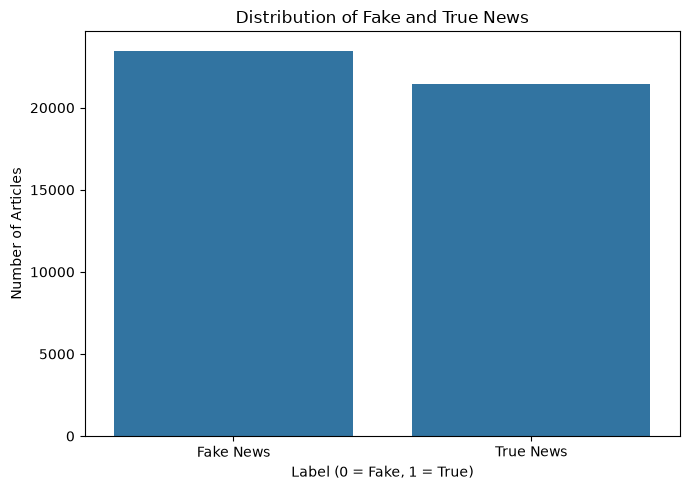

In [396]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=news_df,
    x="label"
)

plt.title("Distribution of Fake and True News")
plt.xlabel("Label (0 = Fake, 1 = True)")
plt.ylabel("Number of Articles")
plt.xticks([0, 1], ["Fake News", "True News"])

plt.tight_layout()
plt.show()

In [397]:
# Calculate the number of words in each article
news_df["word_count"] = news_df["text"].str.split().str.len()

print("Word count statistics:")
print(
    news_df.groupby("label")["word_count"]
    .describe()
    .round(2)
)

Word count statistics:
         count    mean     std  min    25%    50%    75%     max
label                                                           
0      23481.0  423.20  408.39  0.0  240.0  363.0  506.0  8135.0
1      21417.0  385.64  274.01  0.0  148.0  359.0  525.0  5172.0


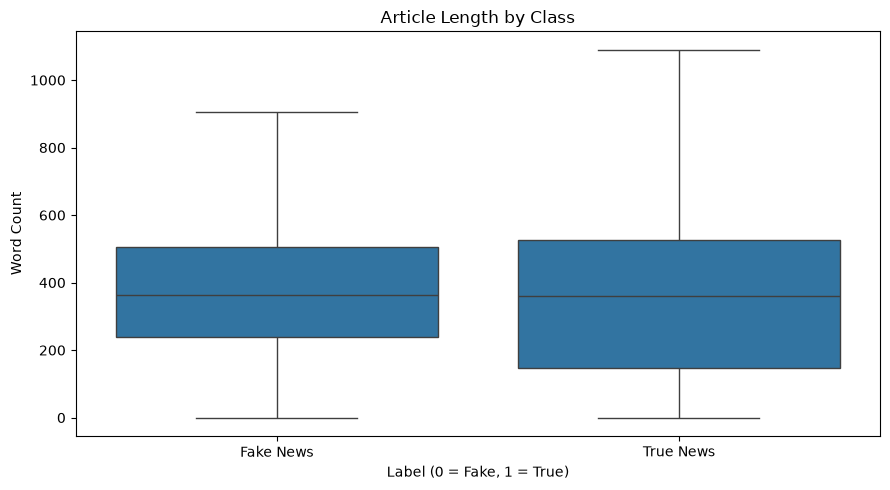

In [398]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=news_df,
    x="label",
    y="word_count",
    showfliers=False
)

plt.title("Article Length by Class")
plt.xlabel("Label (0 = Fake, 1 = True)")
plt.ylabel("Word Count")
plt.xticks([0, 1], ["Fake News", "True News"])

plt.tight_layout()
plt.show()

In [399]:
print("Example of fake news:")
print(news_df[news_df["label"] == 0]["text"].iloc[0])

print("\n" + "=" * 80 + "\n")

print("Example of true news:")
print(news_df[news_df["label"] == 1]["text"].iloc[0])

Example of fake news:
21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocative statements on Judge Jeanine Pirro s show recently. While discussing the halt that was imposed on President Trump s Executive Order on travel. Stein referred to the judgement by the 9th Circuit Court in Washington state as a  Coup d tat against the executive branch and against the constitution.  Stein went on to call the Judges in Seattle  political puppets  and the judiciary  political pawns. Watch the interview below for the complete statements and note the stark contrast to the rhetoric of the leftist media and pundits who neglect to note that no court has ever blocked any Presidential orders in immigration in the past or discuss the legal efficacy of the halt or the actual text of the Executive Order.READ MORE TRUMP NEWS AT: 21st Century Wire Trump FilesSUPPORT OUR 

In [400]:
# Count articles with empty or whitespace-only text
empty_text = news_df["text"].fillna("").str.strip().eq("")

print("Empty article texts:", empty_text.sum())

print("\nEmpty texts by label:")
print(news_df.loc[empty_text, "label"].value_counts())

# Inspect a few examples, if any exist
display(news_df.loc[empty_text, ["title", "text", "label"]].head(10))

Empty article texts: 631

Empty texts by label:
label
0    630
1      1
Name: count, dtype: int64


,title,text,label
11,WHERE’S HILLARY? CLINTON SPOTTED Dining Alone,,0
41,WHOA! RUSH LIMBAUGH RIPS Into Republicans Who ...,,0
177,HILLARY TAKES CREDIT For The Arab Spring Disas...,,0
324,CHILLING! FOX REPORTER JAMES ROSEN Recounts Be...,,0
400,LIVE FEED: INAUGURATION 2017!,,0
424,WHICH ONE OF THESE PEOPLE Tried to Lecture the...,,0
431,UNREAL! OBAMA BLAMES SYRIAN CIVIL WAR ON CLIMA...,,0
458,MICHAEL FLYNN’S LAWYER Releases Statement Scor...,,0
491,BOOM! JULIAN ASSANGE OF WIKILEAKS Drops A Trut...,,0
596,BLACK REPUBLICAN AND BRILLIANT NEUROSURGEON AN...,,0


In [401]:
# Count repeated article bodies, including identical text with different labels
duplicate_text = news_df.duplicated(
    subset=["text"],
    keep=False
)

print("Rows belonging to repeated article texts:", duplicate_text.sum())

print("\nRepeated article texts by label:")
print(news_df.loc[duplicate_text, "label"].value_counts())

# Inspect a few repeated examples
display(
    news_df.loc[
        duplicate_text,
        ["title", "text", "label"]
    ].head(10)
)

Rows belonging to repeated article texts: 11392

Repeated article texts by label:
label
0    10954
1      438
Name: count, dtype: int64


,title,text,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",0
7,STAND UP AND CHEER! UKIP Party Leader SLAMS Ge...,He s been Europe s version of the outspoken Te...,0
11,WHERE’S HILLARY? CLINTON SPOTTED Dining Alone,,0
21,BOOM! KELLYANNE CONWAY Schools CNN’s Anderson ...,Kellyanne Conway went at it with Anderson Coop...,0
29,"Factbox - Battle for Raqqa, Islamic State's Sy...",BEIRUT (Reuters) - The battle for the city of ...,1
33,OUCH! NEW EMAILS Show Hillary Didn’t Want To F...,Former Secretary of State Hillary Clinton once...,0
37,#CrookedHillary Uses Twitter To Accuse Trump O...,Hillary Clinton is bending over backwards to c...,0
41,WHOA! RUSH LIMBAUGH RIPS Into Republicans Who ...,,0
42,WATCH: AMAZING THING HAPPENED When H.S. Valedi...,A 70-year tradition at East Liverpool High Sch...,0
45,ELEMENTARY SCHOOL PLANS ‘BLACKS ONLY’ FIELD TR...,Because there wouldn t be any outrage over a ...,0


In [402]:
# Group articles by their exact text
text_label_counts = (
    news_df.groupby("text")["label"]
    .nunique()
)

# Find texts that have more than one distinct label
conflicting_texts = text_label_counts[
    text_label_counts > 1
]

print(
    "Number of article texts with conflicting labels:",
    len(conflicting_texts)
)

Number of article texts with conflicting labels: 1


In [403]:
# Count occurrences of each exact text
text_counts = news_df["text"].value_counts()

print("Number of unique article texts:", news_df["text"].nunique())

print("\nMost frequently repeated article texts:")
display(text_counts.head(10))

Number of unique article texts: 38646

Most frequently repeated article texts:


text
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

In [404]:
# Remove articles whose text is empty or contains only whitespace
news_clean = news_df.loc[
    news_df["text"].fillna("").str.strip().ne("")
].copy()

news_clean = news_clean.reset_index(drop=True)

print("Original dataset size:", len(news_df))
print("Dataset after removing empty text:", len(news_clean))
print("Articles removed:", len(news_df) - len(news_clean))

print("\nClass distribution after removal:")
print(news_clean["label"].value_counts())

Original dataset size: 44898
Dataset after removing empty text: 44267
Articles removed: 631

Class distribution after removal:
label
0    22851
1    21416
Name: count, dtype: int64


In [405]:
# Identify the conflicting article texts
conflict_mask = news_clean["text"].isin(
    conflicting_texts.index
)

# Display all records containing conflicting text
conflict_records = news_clean.loc[
    conflict_mask,
    ["title", "text", "subject", "date", "label"]
]

display(conflict_records)

,title,text,subject,date,label


In [406]:
# Remove articles with conflicting labels
news_clean = news_clean.loc[
    ~conflict_mask
].copy()

# Remove exact duplicate article bodies
news_clean = news_clean.drop_duplicates(
    subset=["text"],
    keep="first"
).reset_index(drop=True)

print("Dataset after cleaning:", news_clean.shape)

print("\nClass distribution:")
print(news_clean["label"].value_counts())

print("\nRemaining duplicate texts:",
      news_clean["text"].duplicated().sum())

print("\nMissing values:")
print(news_clean.isnull().sum())

Dataset after cleaning: (38644, 6)

Class distribution:
label
1    21191
0    17453
Name: count, dtype: int64

Remaining duplicate texts: 0

Missing values:
title         0
text          0
subject       0
date          0
label         0
word_count    0
dtype: int64


In [407]:
# Separate features and target
X = news_clean["text"]
y = news_clean["label"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature example:")
print(X.iloc[0][:500])

print("\nTarget example:")
print(y.iloc[0])

Features shape: (38644,)
Target shape: (38644,)

Feature example:
21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocative statements on Judge Jeanine Pirro s show recently. While discussing the halt that was imposed on President Trump s Executive Order on travel. Stein referred to the judgement by the 9th Circuit Court in Washington state as a  Coup d tat against the executive branch and against the constitution.  Stein

Target example:
0


In [408]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 30915
Testing samples: 7729

Training class distribution:
label
1    16953
0    13962
Name: count, dtype: int64

Testing class distribution:
label
1    4238
0    3491
Name: count, dtype: int64


In [409]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create the machine learning pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Model pipeline created successfully!")

Model pipeline created successfully!


In [410]:
# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Model Accuracy: 98.84 %

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.99      3491
   True News       0.99      0.99      0.99      4238

    accuracy                           0.99      7729
   macro avg       0.99      0.99      0.99      7729
weighted avg       0.99      0.99      0.99      7729



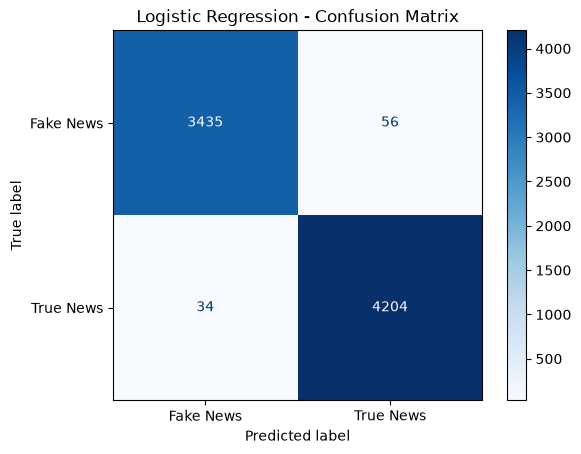

In [411]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Generate predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed evaluation
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Fake News", "True News"]
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake News", "True News"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [412]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd

In [413]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        random_state=42,
        max_iter=3000
    )
}

In [414]:
results = []

for name, classifier in models.items():

    # Create pipeline
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),

        ("classifier", classifier)
    ])

    print(f"Training {name}...")

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    predictions = pipeline.predict(X_test)

    # Evaluate
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

# Create comparison table
results_df = pd.DataFrame(results)

# Display results in percentage
results_df.iloc[:, 1:] = results_df.iloc[:, 1:] * 100

display(
    results_df.round(2).sort_values(
        by="F1 Score",
        ascending=False
    )
)

Training Logistic Regression...
Training Multinomial Naive Bayes...
Training Linear SVM...


,Model,Accuracy,Precision,Recall,F1 Score
2,Linear SVM,99.57,99.48,99.74,99.61
0,Logistic Regression,98.84,98.69,99.20,98.94
1,Multinomial Naive Bayes,95.92,96.06,96.53,96.29


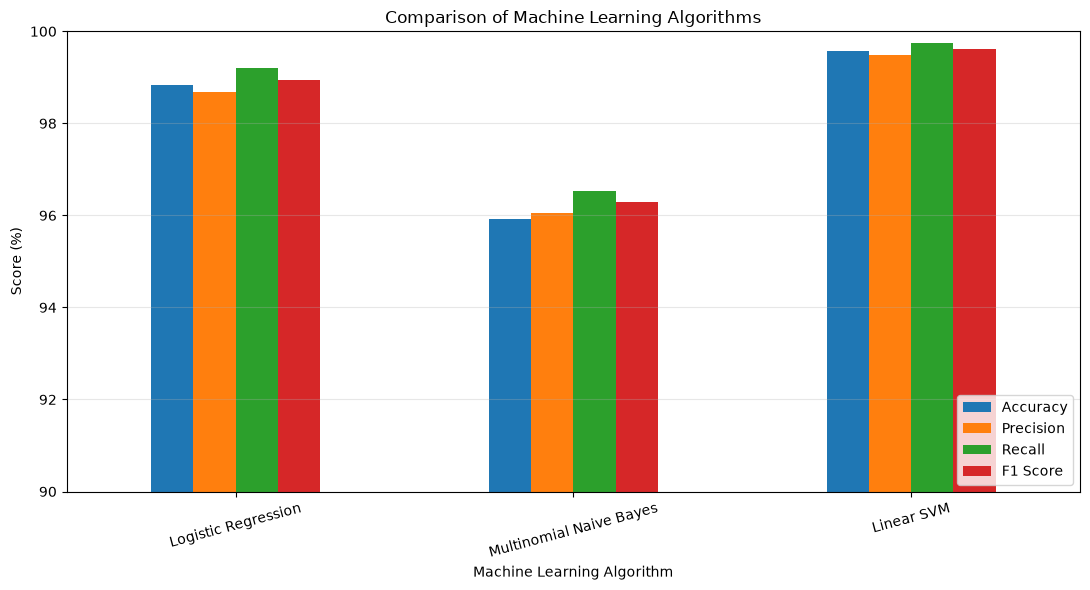

In [415]:
results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of Machine Learning Algorithms")
plt.ylabel("Score (%)")
plt.xlabel("Machine Learning Algorithm")
plt.ylim(90, 100)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [416]:
# Create Linear SVM pipeline
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=3000
    ))
])

# Train
svm_model.fit(X_train, y_train)

# Predict
svm_predictions = svm_model.predict(X_test)

# Detailed report
print(classification_report(
    y_test,
    svm_predictions,
    target_names=["Fake News", "True News"]
))

              precision    recall  f1-score   support

   Fake News       1.00      0.99      1.00      3491
   True News       0.99      1.00      1.00      4238

    accuracy                           1.00      7729
   macro avg       1.00      1.00      1.00      7729
weighted avg       1.00      1.00      1.00      7729



In [417]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

print("Linear SVM - Macro Evaluation")

print("Macro Precision:",
      round(precision_score(y_test, svm_predictions,
                            average="macro") * 100, 2))

print("Macro Recall:",
      round(recall_score(y_test, svm_predictions,
                         average="macro") * 100, 2))

print("Macro F1:",
      round(f1_score(y_test, svm_predictions,
                     average="macro") * 100, 2))

Linear SVM - Macro Evaluation
Macro Precision: 99.58
Macro Recall: 99.56
Macro F1: 99.57


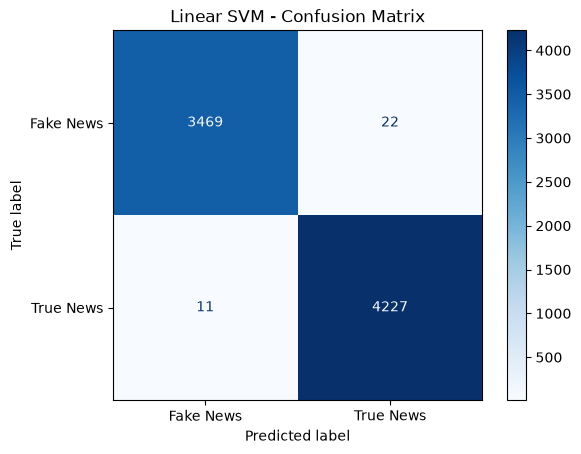

In [418]:
svm_cm = confusion_matrix(y_test, svm_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=svm_cm,
    display_labels=["Fake News", "True News"]
)

disp.plot(cmap="Blues")
plt.title("Linear SVM - Confusion Matrix")
plt.show()

In [419]:
print(svm_cm)

[[3469   22]
 [  11 4227]]


In [420]:
import numpy as np
import pandas as pd

# Extract trained TF-IDF vectorizer and SVM classifier
tfidf = svm_model.named_steps["tfidf"]
svm = svm_model.named_steps["classifier"]

# Get feature names and coefficients
feature_names = tfidf.get_feature_names_out()
coefficients = svm.coef_[0]

# Top 20 features for True News
true_indices = np.argsort(coefficients)[-20:][::-1]

true_features = pd.DataFrame({
    "Word/Phrase": feature_names[true_indices],
    "Weight": coefficients[true_indices]
})

# Top 20 features for Fake News
fake_indices = np.argsort(coefficients)[:20]

fake_features = pd.DataFrame({
    "Word/Phrase": feature_names[fake_indices],
    "Weight": coefficients[fake_indices]
})

print("Features favouring TRUE NEWS:")
display(true_features)

print("\nFeatures favouring FAKE NEWS:")
display(fake_features)

Features favouring TRUE NEWS:


,Word/Phrase,Weight
0,reuters,12.693458
1,said,4.476842
2,washington reuters,4.438450
3,reuters the,3.009899
4,said on,2.790181
5,on wednesday,2.376481
6,on tuesday,2.359805
7,on,2.306019
8,president donald,2.139356
9,on thursday,2.133694



Features favouring FAKE NEWS:


,Word/Phrase,Weight
0,via,-5.778382
1,read more,-3.685418
2,read,-2.500077
3,president trump,-2.258978
4,the us,-2.219540
5,sen,-2.102544
6,featured image,-2.002532
7,image,-1.965749
8,this,-1.909423
9,featured,-1.882875


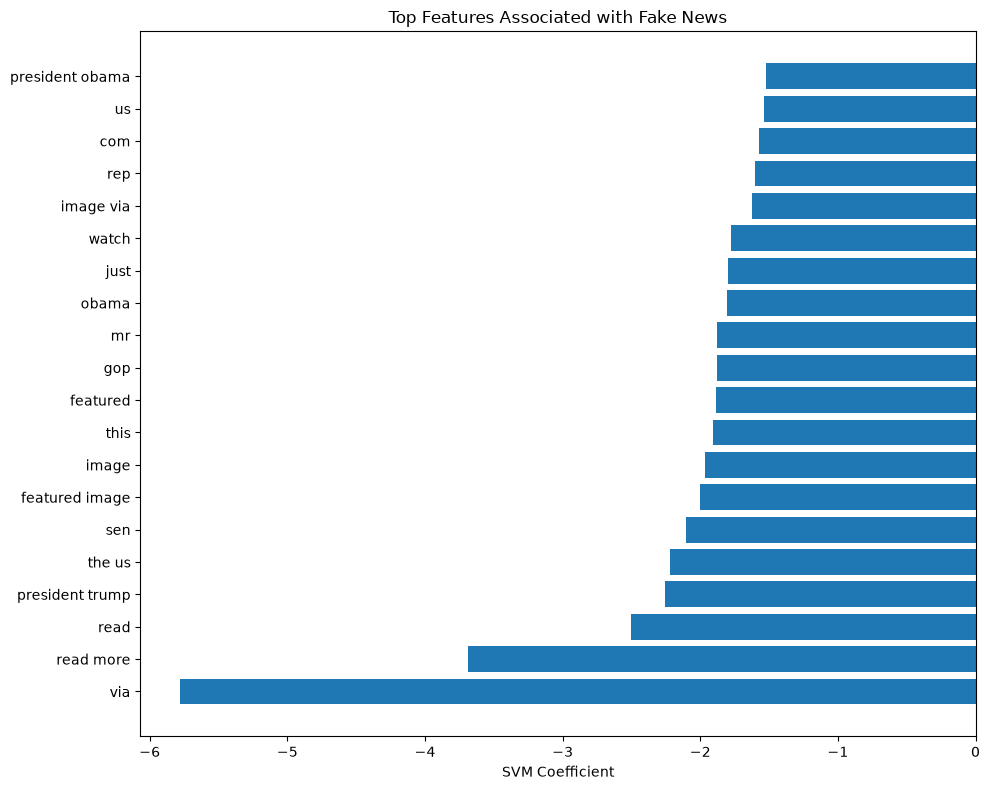

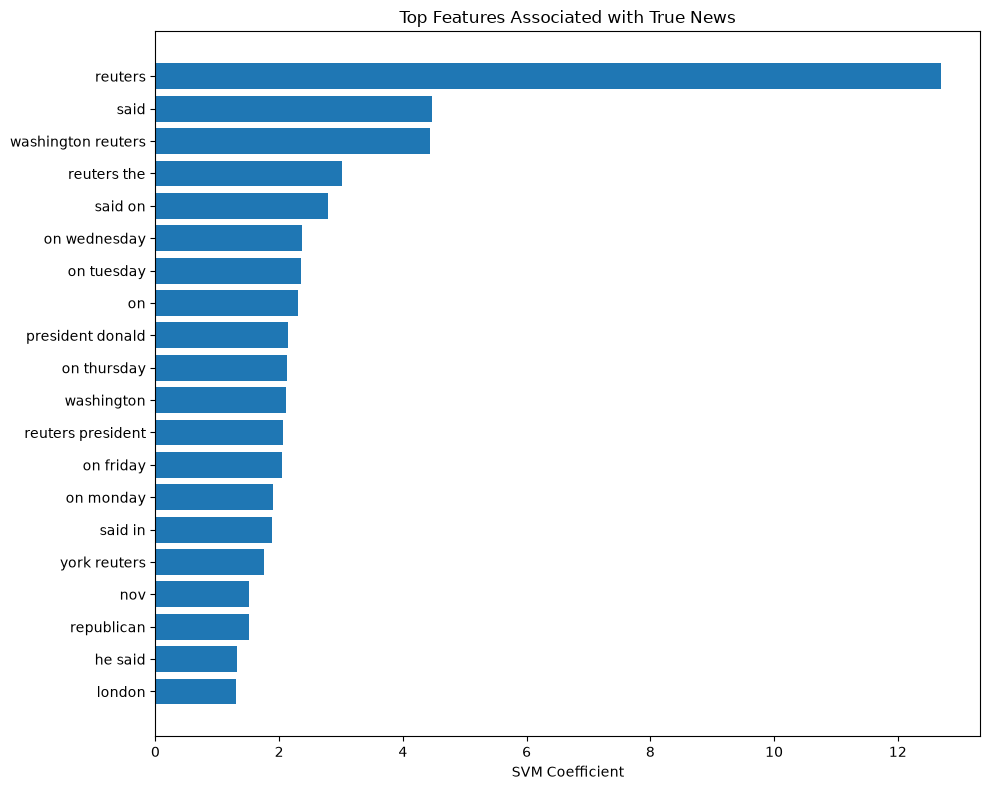

In [421]:
top_true = true_features.sort_values("Weight")

top_fake = fake_features.sort_values("Weight")

plt.figure(figsize=(10, 8))

plt.barh(
    top_fake["Word/Phrase"],
    top_fake["Weight"]
)

plt.title("Top Features Associated with Fake News")
plt.xlabel("SVM Coefficient")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))

plt.barh(
    top_true["Word/Phrase"],
    top_true["Weight"]
)

plt.title("Top Features Associated with True News")
plt.xlabel("SVM Coefficient")
plt.tight_layout()
plt.show()

In [422]:
# Find incorrectly classified test articles
misclassified = X_test[
    svm_predictions != y_test
]

misclassified_results = pd.DataFrame({
    "Actual": y_test.loc[misclassified.index],
    "Predicted": svm_predictions[
        np.where(svm_predictions != y_test)[0]
    ],
    "Text": misclassified.values
})

misclassified_results["Actual"] = (
    misclassified_results["Actual"]
    .map({0: "Fake", 1: "True"})
)

misclassified_results["Predicted"] = (
    misclassified_results["Predicted"]
    .map({0: "Fake", 1: "True"})
)

print("Total misclassified articles:", len(misclassified_results))

display(misclassified_results.head(10))

Total misclassified articles: 33


,Actual,Predicted,Text
5043,Fake,True,President Donald Trump welcomed India s Prime ...
35534,Fake,True,This could be YUGE news for conservatives who ...
22143,True,Fake,"MIDDLETOWN, CONN. - Two years ago, Judy Konopk..."
2013,Fake,True,Just when you thought the 2014 election result...
35740,True,Fake,NEW YORK (Thomson Reuters Foundation) - As a S...
36140,Fake,True,The last time a pope got involved in politics ...
897,Fake,True,***Warning*** Graphic photo and videoThank goo...
4892,True,Fake,(Reuters) - Below are the highlights from Reut...
5934,Fake,True,Here s the thing about being the leader of the...
883,Fake,True,Jill Stein got less than 1% of the vote nation...


In [423]:
keywords = [
    "reuters",
    "read more",
    "featured image",
    "via",
    "washington reuters"
]

keyword_results = []

for keyword in keywords:

    fake_count = news_clean.loc[
        news_clean["label"] == 0,
        "text"
    ].str.contains(keyword, case=False, regex=False).sum()

    true_count = news_clean.loc[
        news_clean["label"] == 1,
        "text"
    ].str.contains(keyword, case=False, regex=False).sum()

    keyword_results.append({
        "Keyword": keyword,
        "Fake Count": fake_count,
        "True Count": true_count,
        "Fake Percentage": round(
            fake_count / 17453 * 100, 2
        ),
        "True Percentage": round(
            true_count / 21191 * 100, 2
        )
    })

keyword_df = pd.DataFrame(keyword_results)

display(keyword_df)

,Keyword,Fake Count,True Count,Fake Percentage,True Percentage
0,reuters,220,21154,1.26,99.83
1,read more,1714,9,9.82,0.04
2,featured image,8160,0,46.75,0.00
3,via,9863,1100,56.51,5.19
4,washington reuters,0,0,0.00,0.00


In [424]:
import re

# Create copies of training and testing text
X_train_no_reuters = X_train.apply(
    lambda text: re.sub(
        r"\breuters\b",
        " ",
        text,
        flags=re.IGNORECASE
    )
)

X_test_no_reuters = X_test.apply(
    lambda text: re.sub(
        r"\breuters\b",
        " ",
        text,
        flags=re.IGNORECASE
    )
)

# Create a fresh SVM pipeline
svm_no_reuters = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=3000
    ))
])

# Train without Reuters
svm_no_reuters.fit(
    X_train_no_reuters,
    y_train
)

# Predict
pred_no_reuters = svm_no_reuters.predict(
    X_test_no_reuters
)

# Evaluate
print(
    "Original SVM Accuracy:",
    round(accuracy_score(y_test, svm_predictions) * 100, 2),
    "%"
)

print(
    "SVM Accuracy without Reuters:",
    round(accuracy_score(y_test, pred_no_reuters) * 100, 2),
    "%"
)

print("\nClassification Report without Reuters:")

print(classification_report(
    y_test,
    pred_no_reuters,
    target_names=["Fake News", "True News"]
))

Original SVM Accuracy: 99.57 %
SVM Accuracy without Reuters: 99.29 %

Classification Report without Reuters:
              precision    recall  f1-score   support

   Fake News       0.99      0.99      0.99      3491
   True News       0.99      0.99      0.99      4238

    accuracy                           0.99      7729
   macro avg       0.99      0.99      0.99      7729
weighted avg       0.99      0.99      0.99      7729



In [425]:
import re

def remove_publishing_artifacts(text, remove_via=False):

    # Remove publisher and website formatting
    patterns = [
        r"\breuters\b",
        r"\bread\s+more\b",
        r"\bfeatured\s+image\b"
    ]

    if remove_via:
        patterns.append(r"\bvia\b")

    for pattern in patterns:
        text = re.sub(
            pattern,
            " ",
            text,
            flags=re.IGNORECASE
        )

    return text

In [426]:
# Experiment A: Remove Reuters and publishing phrases
X_train_clean_a = X_train.apply(
    lambda x: remove_publishing_artifacts(x)
)

X_test_clean_a = X_test.apply(
    lambda x: remove_publishing_artifacts(x)
)

# Experiment B: Also remove the word "via"
X_train_clean_b = X_train.apply(
    lambda x: remove_publishing_artifacts(x, remove_via=True)
)

X_test_clean_b = X_test.apply(
    lambda x: remove_publishing_artifacts(x, remove_via=True)
)

In [427]:
def train_svm_experiment(X_tr, X_te, experiment_name):

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(
            random_state=42,
            max_iter=3000
        ))
    ])

    pipeline.fit(X_tr, y_train)

    predictions = pipeline.predict(X_te)

    return {
        "Experiment": experiment_name,
        "Accuracy": accuracy_score(y_test, predictions) * 100,
        "Macro Precision": precision_score(
            y_test, predictions, average="macro"
        ) * 100,
        "Macro Recall": recall_score(
            y_test, predictions, average="macro"
        ) * 100,
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ) * 100
    }


ablation_results = []

ablation_results.append({
    "Experiment": "Original SVM",
    "Accuracy": accuracy_score(y_test, svm_predictions) * 100,
    "Macro Precision": precision_score(
        y_test, svm_predictions, average="macro"
    ) * 100,
    "Macro Recall": recall_score(
        y_test, svm_predictions, average="macro"
    ) * 100,
    "Macro F1": f1_score(
        y_test, svm_predictions, average="macro"
    ) * 100
})

ablation_results.append(
    train_svm_experiment(
        X_train_clean_a,
        X_test_clean_a,
        "Without publishing phrases"
    )
)

ablation_results.append(
    train_svm_experiment(
        X_train_clean_b,
        X_test_clean_b,
        "Without publishing phrases and via"
    )
)

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(2))

,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Original SVM,99.57,99.58,99.56,99.57
1,Without publishing phrases,99.15,99.16,99.12,99.14
2,Without publishing phrases and via,99.07,99.09,99.03,99.06


In [428]:
# Subject distribution by class
subject_distribution = pd.crosstab(
    news_clean["subject"],
    news_clean["label"],
    normalize="columns"
) * 100

subject_distribution.columns = [
    "Fake News (%)",
    "True News (%)"
]

display(subject_distribution.round(2))

,Fake News (%),True News (%)
subject,,
Government News,4.98,0.00
Middle-east,2.29,0.00
News,51.85,0.00
US_News,2.19,0.00
left-news,13.83,0.00
politics,24.86,0.00
politicsNews,0.00,52.89
worldnews,0.00,47.11


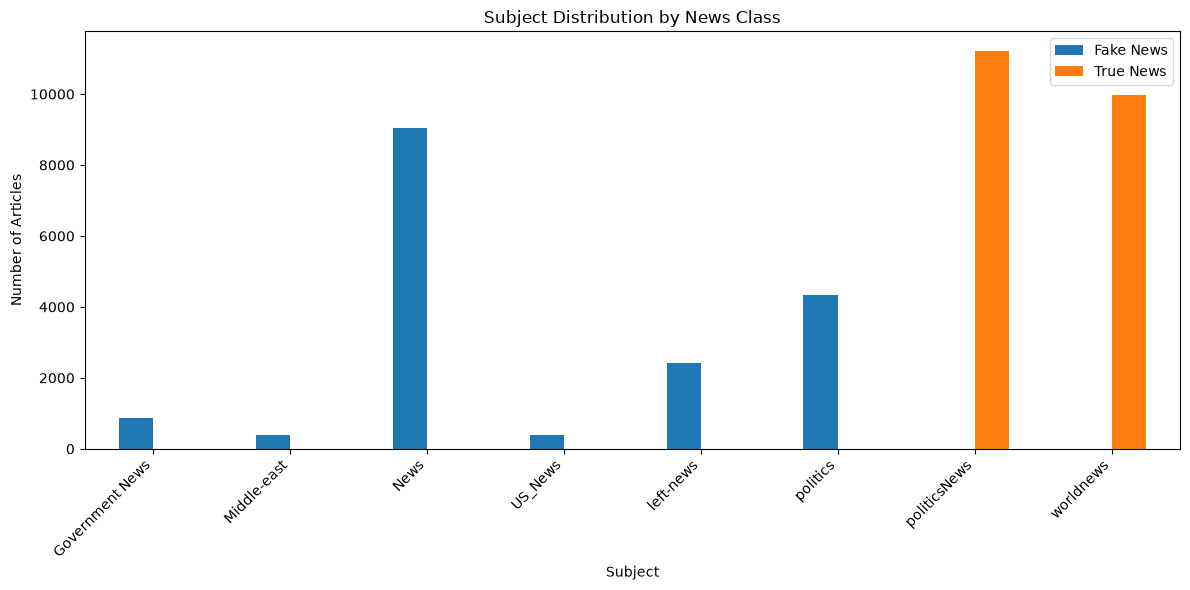

In [429]:
subject_counts = pd.crosstab(
    news_clean["subject"],
    news_clean["label"]
)

subject_counts.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Subject Distribution by News Class")
plt.xlabel("Subject")
plt.ylabel("Number of Articles")
plt.legend(["Fake News", "True News"])
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [430]:
# Inspect original date formats
print("Sample dates:")
display(news_clean["date"].sample(15, random_state=42))

# Convert dates
news_clean["parsed_date"] = pd.to_datetime(
    news_clean["date"],
    errors="coerce",
    utc=True
)

print("\nDate conversion results:")
print("Successfully parsed:",
      news_clean["parsed_date"].notna().sum())

print("Unparsed dates:",
      news_clean["parsed_date"].isna().sum())

print("\nDate ranges by class:")
display(
    news_clean.groupby("label")["parsed_date"]
    .agg(["min", "max"])
)

Sample dates:


35896       April 17, 2017
27985       August 5, 2016
38273    October 16, 2017 
14938         Sep 27, 2017
26787    October 23, 2017 
31111     February 2, 2017
24141      October 5, 2016
17791     February 6, 2016
19872        May 23, 2016 
34806      August 25, 2016
30738    October 18, 2017 
37008     October 19, 2017
25087        June 8, 2017 
26228       July 17, 2017 
2907        April 28, 2016
Name: date, dtype: str


Date conversion results:
Successfully parsed: 10590
Unparsed dates: 28054

Date ranges by class:


,min,max
label,,
0,2015-05-01 00:00:00+00:00,2017-12-31 00:00:00+00:00
1,NaT,NaT


In [431]:
print(news_clean.columns.tolist())
print(news_clean[["date"]].head())

['title', 'text', 'subject', 'date', 'label', 'word_count', 'parsed_date']
                  date
0    February 13, 2017
1       April 5, 2017 
2  September 27, 2017 
3         May 22, 2017
4       June 24, 2016 


In [432]:
news_clean["date"] = pd.to_datetime(
    news_clean["date"],
    errors="coerce",
    utc=True
)

news_clean["year"] = news_clean["date"].dt.year

In [433]:
year_distribution = pd.crosstab(
    news_clean["year"],
    news_clean["label"]
).reindex(columns=[0, 1], fill_value=0)

year_distribution.columns = ["Fake News", "True News"]

print(year_distribution)

        Fake News  True News
year                        
2015.0        180          0
2016.0       6526          0
2017.0       3884          0


In [434]:
print("Columns:", year_distribution.columns)
print("Shape:", year_distribution.shape)

print("\nLabel values:")
print(news_clean["label"].value_counts(dropna=False))

print("\nYear values:")
print(news_clean["year"].value_counts(dropna=False).sort_index())

Columns: Index(['Fake News', 'True News'], dtype='str')
Shape: (3, 2)

Label values:
label
1    21191
0    17453
Name: count, dtype: int64

Year values:
year
2015.0      180
2016.0     6526
2017.0     3884
NaN       28054
Name: count, dtype: int64


In [435]:
year_distribution = pd.crosstab(
    news_clean["year"],
    news_clean["label"]
)

year_distribution = year_distribution.rename(
    columns={
        0: "Fake News",
        1: "True News"
    }
)

display(year_distribution)

label,Fake News
year,
2015.0,180
2016.0,6526
2017.0,3884


In [436]:
print(news_clean.groupby("label")["parsed_date"].agg(
    ["count", "min", "max"]
))

       count                       min                       max
label                                                           
0      10590 2015-05-01 00:00:00+00:00 2017-12-31 00:00:00+00:00
1          0                       NaT                       NaT


In [437]:
print("Fake News date samples:")
display(news_clean[news_clean["label"] == 0]["date"].sample(
    15, random_state=42
))

print("\nTrue News date samples:")
display(news_clean[news_clean["label"] == 1]["date"].sample(
    15, random_state=42
))

Fake News date samples:


38141   2016-05-25 00:00:00+00:00
2621    2017-03-05 00:00:00+00:00
4477                          NaT
41                            NaT
12812                         NaT
27826   2017-12-16 00:00:00+00:00
32563                         NaT
9132                          NaT
24048                         NaT
10250   2016-09-30 00:00:00+00:00
10903                         NaT
22263   2017-11-05 00:00:00+00:00
227     2016-03-11 00:00:00+00:00
32057   2017-04-05 00:00:00+00:00
22166                         NaT
Name: date, dtype: datetime64[us, UTC]


True News date samples:


2145    NaT
23071   NaT
23368   NaT
15779   NaT
15568   NaT
15836   NaT
23772   NaT
11121   NaT
11423   NaT
18668   NaT
12753   NaT
6856    NaT
21962   NaT
6777    NaT
34158   NaT
Name: date, dtype: datetime64[us, UTC]

In [438]:
failed_dates = news_clean[
    news_clean["parsed_date"].isna()
]

print("Failed date counts by label:")
print(failed_dates["label"].value_counts())

print("\nExamples of failed dates:")
display(failed_dates[["date", "label"]].sample(
    min(20, len(failed_dates)),
    random_state=42
))

Failed date counts by label:
label
1    21191
0     6863
Name: count, dtype: int64

Examples of failed dates:


,date,label
4134,NaT,1
15913,NaT,1
26848,NaT,1
31244,NaT,1
34072,NaT,1
2257,NaT,1
5453,NaT,1
17544,NaT,1
31770,NaT,1
23530,NaT,0


In [439]:
news_clean["parsed_date"] = pd.to_datetime(
    news_clean["date"],
    errors="coerce",
    utc=True
)

news_clean["year"] = news_clean["parsed_date"].dt.year

In [440]:
print("Successfully parsed:", news_clean["parsed_date"].notna().sum())
print("Failed dates:", news_clean["parsed_date"].isna().sum())

print("\nDate conversion by class:")
display(
    news_clean.groupby("label")["parsed_date"]
    .agg(["count", "min", "max"])
)

Successfully parsed: 10590
Failed dates: 28054

Date conversion by class:


,count,min,max
label,,,
0,10590,2015-05-01 00:00:00+00:00,2017-12-31 00:00:00+00:00
1,0,NaT,NaT


In [441]:
news_clean["year"] = news_clean["parsed_date"].dt.year

year_distribution = pd.crosstab(
    news_clean["year"],
    news_clean["label"]
).reindex(columns=[0, 1], fill_value=0)

year_distribution.columns = ["Fake News", "True News"]

display(year_distribution)

,Fake News,True News
year,,
2015.0,180,0
2016.0,6526,0
2017.0,3884,0


In [442]:
failed_fake_dates = news_clean[
    (news_clean["label"] == 0) &
    (news_clean["parsed_date"].isna())
]

print("Unique failed date values:")
print(failed_fake_dates["date"].value_counts().head(30))

Unique failed date values:
Series([], Name: count, dtype: int64)


In [443]:
failed_mask = news_clean["parsed_date"].isna()

# Convert only the failed date values to strings before parsing
failed_dates = news_clean.loc[failed_mask, "date"].astype("string").str.strip()

news_clean.loc[failed_mask, "parsed_date"] = pd.to_datetime(
    failed_dates,
    format="%b %d, %Y",
    errors="coerce",
    utc=True
)

In [444]:
print("Successfully parsed:", news_clean["parsed_date"].notna().sum())
print("Still unparsed:", news_clean["parsed_date"].isna().sum())

display(
    news_clean.groupby("label")["parsed_date"]
    .agg(["count", "min", "max"])
)

Successfully parsed: 10590
Still unparsed: 28054


,count,min,max
label,,,
0,10590,2015-05-01 00:00:00+00:00,2017-12-31 00:00:00+00:00
1,0,NaT,NaT


In [445]:
news_clean["year"] = news_clean["parsed_date"].dt.year

year_distribution = pd.crosstab(
    news_clean["year"],
    news_clean["label"]
).reindex(columns=[0, 1], fill_value=0)

year_distribution.columns = ["Fake News", "True News"]

display(year_distribution)

,Fake News,True News
year,,
2015.0,180,0
2016.0,6526,0
2017.0,3884,0


In [446]:
subject_distribution = pd.crosstab(
    news_clean["subject"],
    news_clean["label"],
    normalize="columns"
) * 100

subject_distribution.columns = ["Fake News (%)", "True News (%)"]

display(subject_distribution.round(2))

,Fake News (%),True News (%)
subject,,
Government News,4.98,0.00
Middle-east,2.29,0.00
News,51.85,0.00
US_News,2.19,0.00
left-news,13.83,0.00
politics,24.86,0.00
politicsNews,0.00,52.89
worldnews,0.00,47.11


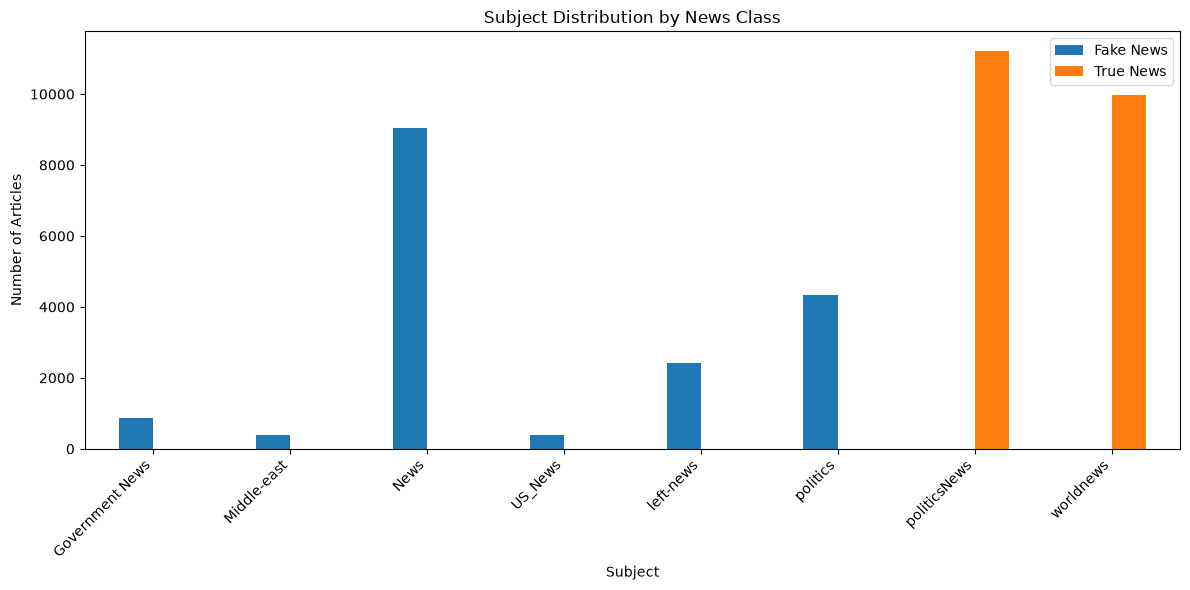

In [447]:
subject_counts = pd.crosstab(
    news_clean["subject"],
    news_clean["label"]
)

subject_counts.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Subject Distribution by News Class")
plt.xlabel("Subject")
plt.ylabel("Number of Articles")
plt.legend(["Fake News", "True News"])
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [448]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

X_subject = news_clean[["subject"]]
y_subject = news_clean["label"]

X_train_sub, X_test_sub, y_train_sub, y_test_sub = train_test_split(
    X_subject,
    y_subject,
    test_size=0.20,
    random_state=42,
    stratify=y_subject
)

subject_model = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

subject_model.fit(X_train_sub, y_train_sub)

subject_predictions = subject_model.predict(X_test_sub)

print("Subject-only accuracy:",
      accuracy_score(y_test_sub, subject_predictions))

print("\nClassification Report:")
print(classification_report(y_test_sub, subject_predictions))

Subject-only accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3491
           1       1.00      1.00      1.00      4238

    accuracy                           1.00      7729
   macro avg       1.00      1.00      1.00      7729
weighted avg       1.00      1.00      1.00      7729



In [449]:
fake_original = pd.read_csv(DATA_DIR / "Fake.csv")
true_original = pd.read_csv(DATA_DIR / "True.csv")

print("Fake dataset:", fake_original.shape)
print("True dataset:", true_original.shape)

print("\nFake columns:")
print(fake_original.columns.tolist())

print("\nTrue columns:")
print(true_original.columns.tolist())

Fake dataset: (23481, 4)
True dataset: (21417, 4)

Fake columns:
['title', 'text', 'subject', 'date']

True columns:
['title', 'text', 'subject', 'date']


In [450]:
print("FAKE NEWS SUBJECTS")
display(fake_original["subject"].value_counts())

print("\nTRUE NEWS SUBJECTS")
display(true_original["subject"].value_counts())

FAKE NEWS SUBJECTS


subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64


TRUE NEWS SUBJECTS


subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64

In [451]:
print("FAKE NEWS EXAMPLES")
display(fake_original[["title", "text", "subject", "date"]].head(5))

print("\nTRUE NEWS EXAMPLES")
display(true_original[["title", "text", "subject", "date"]].head(5))

FAKE NEWS EXAMPLES


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"



TRUE NEWS EXAMPLES


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [452]:
print("FAKE NEWS EXAMPLES")

for i, row in fake_original.head(5).iterrows():
    print(f"\nArticle {i}")
    print("Subject:", row["subject"])
    print("Date:", row["date"])
    print("Title:", row["title"])
    print("Text beginning:", row["text"][:500])
    print("-" * 80)


print("\nTRUE NEWS EXAMPLES")

for i, row in true_original.head(5).iterrows():
    print(f"\nArticle {i}")
    print("Subject:", row["subject"])
    print("Date:", row["date"])
    print("Title:", row["title"])
    print("Text beginning:", row["text"][:500])
    print("-" * 80)

FAKE NEWS EXAMPLES

Article 0
Subject: News
Date: December 31, 2017
Title:  Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing
Text beginning: Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a gr
--------------------------------------------------------------------------------

Article 1
Subject: News
Date: December 31, 2017
Title:  Drunk Bragging Trump Staffer Started Russian Collusion Investigation
Text beginning: House Intelligence Committee Chairman Devin Nunes is going to have a bad day. He s been under the assumpt

In [453]:
import re

def remove_reuters_attribution(text):
    text = re.sub(
        r"^\s*WASHINGTON\s*\(Reuters\)\s*-\s*",
        "",
        text,
        flags=re.IGNORECASE
    )
    return text

X_no_reuters = X.apply(remove_reuters_attribution)

X_train_nr, X_test_nr, y_train_nr, y_test_nr = train_test_split(
    X_no_reuters,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

svm_no_reuters = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(random_state=42, max_iter=3000))
])

svm_no_reuters.fit(X_train_nr, y_train_nr)

predictions_nr = svm_no_reuters.predict(X_test_nr)

print("Accuracy without Reuters attribution:",
      accuracy_score(y_test_nr, predictions_nr))

print("\nClassification Report:")
print(classification_report(y_test_nr, predictions_nr))

Accuracy without Reuters attribution: 0.994436537715099

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      3491
           1       0.99      1.00      0.99      4238

    accuracy                           0.99      7729
   macro avg       0.99      0.99      0.99      7729
weighted avg       0.99      0.99      0.99      7729



In [454]:
import re

def remove_text_artifacts(text):
    text = str(text)

    # Remove Reuters mentions
    text = re.sub(r"\bReuters\b", " ", text, flags=re.IGNORECASE)

    # Remove common formatting phrases
    text = re.sub(
        r"\b(read more|featured image|image via)\b",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [455]:
X_artifact_removed = X.apply(remove_text_artifacts)

X_train_ar, X_test_ar, y_train_ar, y_test_ar = train_test_split(
    X_artifact_removed,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

svm_artifact_removed = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(random_state=42, max_iter=3000))
])

svm_artifact_removed.fit(X_train_ar, y_train_ar)

predictions_ar = svm_artifact_removed.predict(X_test_ar)

print("Accuracy:", accuracy_score(y_test_ar, predictions_ar))
print("\nClassification Report:")
print(classification_report(y_test_ar, predictions_ar))

Accuracy: 0.9918488808384008

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3491
           1       0.99      0.99      0.99      4238

    accuracy                           0.99      7729
   macro avg       0.99      0.99      0.99      7729
weighted avg       0.99      0.99      0.99      7729



In [456]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

fake_text = X_artifact_removed[y == 0]
true_text = X_artifact_removed[y == 1]

vectorizer = CountVectorizer(
    stop_words="english",
    max_features=30
)

fake_matrix = vectorizer.fit_transform(fake_text)

fake_word_counts = pd.Series(
    fake_matrix.sum(axis=0).A1,
    index=vectorizer.get_feature_names_out()
).sort_values(ascending=False)

vectorizer = CountVectorizer(
    stop_words="english",
    max_features=30
)

true_matrix = vectorizer.fit_transform(true_text)

true_word_counts = pd.Series(
    true_matrix.sum(axis=0).A1,
    index=vectorizer.get_feature_names_out()
).sort_values(ascending=False)

print("Most common Fake News words:")
display(fake_word_counts)

print("\nMost common True News words:")
display(true_word_counts)

Most common Fake News words:


trump         68068
said          24803
people        21187
president     20790
just          16740
donald        15284
like          14358
clinton       13527
obama         13377
time          10705
new           10395
white         10305
news          10207
hillary        9944
state          9489
twitter        9267
right          8893
campaign       8834
house          8427
know           8404
don            8209
american       8181
america        8149
going          7976
republican     7975
media          7824
states         7585
year           7398
make           7301
did            7289
dtype: int64


Most common True News words:


said          97814
trump         54072
president     27855
state         20781
government    18550
new           16735
house         16462
states        16411
republican    16135
united        15360
people        15076
year          14583
told          14061
washington    12884
party         12589
election      12171
campaign      10535
donald        10370
security      10005
percent        9920
north          9697
clinton        9465
white          9452
court          9356
obama          9330
senate         9161
country        8779
china          8714
minister       8544
officials      8364
dtype: int64

In [457]:
def get_normalized_word_frequency(texts):
    vectorizer = CountVectorizer(stop_words="english")

    matrix = vectorizer.fit_transform(texts)

    total_words = matrix.sum()

    frequencies = pd.Series(
        matrix.sum(axis=0).A1,
        index=vectorizer.get_feature_names_out()
    )

    return (frequencies / total_words * 1000).sort_values(
        ascending=False
    )


fake_frequency = get_normalized_word_frequency(fake_text)
true_frequency = get_normalized_word_frequency(true_text)

comparison = pd.concat(
    [
        fake_frequency.rename("Fake per 1000 words"),
        true_frequency.rename("True per 1000 words")
    ],
    axis=1
).fillna(0)

comparison["Difference"] = (
    comparison["Fake per 1000 words"] -
    comparison["True per 1000 words"]
)

print("Words more frequent in Fake News:")
display(comparison.sort_values(
    "Difference", ascending=False
).head(20).round(3))

print("\nWords more frequent in True News:")
display(comparison.sort_values(
    "Difference", ascending=True
).head(20).round(3))

Words more frequent in Fake News:


,Fake per 1000 words,True per 1000 words,Difference
trump,17.647,11.925,5.722
just,4.340,0.973,3.367
like,3.722,1.022,2.700
people,5.493,3.325,2.168
hillary,2.578,0.602,1.976
twitter,2.403,0.550,1.853
know,2.179,0.477,1.702
donald,3.962,2.287,1.676
america,2.113,0.541,1.571
video,1.698,0.200,1.498



Words more frequent in True News:


,Fake per 1000 words,True per 1000 words,Difference
said,6.430,21.572,-15.141
government,1.626,4.091,-2.465
state,2.460,4.583,-2.123
united,1.530,3.387,-1.858
washington,0.984,2.841,-1.858
minister,0.172,1.884,-1.712
china,0.242,1.922,-1.679
states,1.966,3.619,-1.653
north,0.505,2.139,-1.634
republican,2.068,3.558,-1.491


In [458]:
def remove_political_names(text):
    text = str(text)

    names = [
        "trump",
        "donald",
        "clinton",
        "hillary",
        "obama",
        "barack"
    ]

    for name in names:
        text = re.sub(
            rf"\b{name}\b",
            " ",
            text,
            flags=re.IGNORECASE
        )

    text = re.sub(r"\s+", " ", text).strip()

    return text

In [459]:
X_no_names = X_artifact_removed.apply(remove_political_names)

X_train_names, X_test_names, y_train_names, y_test_names = train_test_split(
    X_no_names,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

svm_no_names = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(random_state=42, max_iter=3000))
])

svm_no_names.fit(X_train_names, y_train_names)

predictions_names = svm_no_names.predict(X_test_names)

print("Accuracy without political names:",
      accuracy_score(y_test_names, predictions_names))

print("\nClassification Report:")
print(classification_report(y_test_names, predictions_names))

Accuracy without political names: 0.9914607323068961

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3491
           1       0.99      0.99      0.99      4238

    accuracy                           0.99      7729
   macro avg       0.99      0.99      0.99      7729
weighted avg       0.99      0.99      0.99      7729



In [460]:
def remove_reporting_phrases(text):
    text = str(text)

    phrases = [
        "said",
        "told",
        "according to",
        "reuters",
        "reported",
        "officials",
        "sources"
    ]

    for phrase in phrases:
        text = re.sub(
            rf"\b{re.escape(phrase)}\b",
            " ",
            text,
            flags=re.IGNORECASE
        )

    text = re.sub(r"\s+", " ", text).strip()

    return text


X_no_reporting = X_no_names.apply(remove_reporting_phrases)

X_train_report, X_test_report, y_train_report, y_test_report = train_test_split(
    X_no_reporting,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

svm_no_reporting = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=3000
    ))
])

svm_no_reporting.fit(X_train_report, y_train_report)

predictions_report = svm_no_reporting.predict(X_test_report)

print("Accuracy:", accuracy_score(y_test_report, predictions_report))
print("\nClassification Report:")
print(classification_report(y_test_report, predictions_report))

Accuracy: 0.9912019666192263

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3491
           1       0.99      0.99      0.99      4238

    accuracy                           0.99      7729
   macro avg       0.99      0.99      0.99      7729
weighted avg       0.99      0.99      0.99      7729



In [461]:
print(news_clean["parsed_date"].min())
print(news_clean["parsed_date"].max())

print(
    news_clean.groupby(
        news_clean["parsed_date"].dt.year
    )["label"].value_counts().unstack(fill_value=0)
)

2015-05-01 00:00:00+00:00
2017-12-31 00:00:00+00:00
label           0
parsed_date      
2015.0        180
2016.0       6526
2017.0       3884


In [472]:
print("Current dataset shape:", news_clean.shape)

print("\nLabels:")
print(news_clean["label"].value_counts())

print("\nYear and label distribution:")
print(pd.crosstab(news_clean["year"], news_clean["label"]))

print("\nSubjects:")
print(news_clean["subject"].value_counts())

Current dataset shape: (38644, 8)

Labels:
label
1    21191
0    17453
Name: count, dtype: int64

Year and label distribution:
label      0
year        
2015.0   180
2016.0  6526
2017.0  3884

Subjects:
subject
politicsNews       11208
worldnews           9983
News                9050
politics            4338
left-news           2413
Government News      869
Middle-east          400
US_News              383
Name: count, dtype: int64


In [473]:
print("Original date examples by label:")

print("\nFake articles:")
print(news_clean.loc[news_clean["label"] == 0, "date"].head(10))

print("\nTrue articles:")
print(news_clean.loc[news_clean["label"] == 1, "date"].head(10))

print("\nParsed dates by label:")
print(news_clean.groupby("label")["parsed_date"].agg(
    ["count", "min", "max"]
))

Original date examples by label:

Fake articles:
0    2017-02-13 00:00:00+00:00
3    2017-05-22 00:00:00+00:00
5    2016-06-22 00:00:00+00:00
6                          NaT
7                          NaT
13                         NaT
15   2016-05-04 00:00:00+00:00
16   2017-05-07 00:00:00+00:00
17   2017-06-08 00:00:00+00:00
19   2016-03-01 00:00:00+00:00
Name: date, dtype: datetime64[us, UTC]

True articles:
1    NaT
2    NaT
4    NaT
8    NaT
9    NaT
10   NaT
11   NaT
12   NaT
14   NaT
18   NaT
Name: date, dtype: datetime64[us, UTC]

Parsed dates by label:
       count                       min                       max
label                                                           
0      10590 2015-05-01 00:00:00+00:00 2017-12-31 00:00:00+00:00
1          0                       NaT                       NaT


In [474]:
print(pd.crosstab(
    news_clean["parsed_date"].dt.year,
    news_clean["label"],
    dropna=False
))

label           0      1
parsed_date             
2015.0        180      0
2016.0       6526      0
2017.0       3884      0
NaN          6863  21191


In [475]:
fake_original = pd.read_csv(DATA_DIR / "Fake.csv")
true_original = pd.read_csv(DATA_DIR / "True.csv")

print("Fake dataset:", fake_original.shape)
print("True dataset:", true_original.shape)

print("\nFake date examples:")
print(fake_original["date"].head())

print("\nTrue date examples:")
print(true_original["date"].head())

Fake dataset: (23481, 4)
True dataset: (21417, 4)

Fake date examples:
0    December 31, 2017
1    December 31, 2017
2    December 30, 2017
3    December 29, 2017
4    December 25, 2017
Name: date, dtype: str

True date examples:
0    December 31, 2017 
1    December 29, 2017 
2    December 31, 2017 
3    December 30, 2017 
4    December 29, 2017 
Name: date, dtype: str


In [476]:
# Reconstruct the original dataset with labels
fake_source = fake_original.copy()
fake_source["label"] = 0

true_source = true_original.copy()
true_source["label"] = 1

source_dates = pd.concat(
    [fake_source, true_source],
    ignore_index=True
)[["title", "text", "label", "date"]]

# Check whether any matching articles have conflicting dates
conflicts = (
    source_dates.groupby(["title", "text", "label"])["date"]
    .nunique()
)

if (conflicts > 1).any():
    raise ValueError(
        "Some identical articles have conflicting dates. "
        "We need to inspect these before restoring dates."
    )

# Create a unique date lookup
date_lookup = source_dates.drop_duplicates(
    subset=["title", "text", "label"]
)

# Preserve the current row order
news_clean = news_clean.reset_index(drop=True)
news_clean["_row_order"] = range(len(news_clean))

# Restore original date strings by matching articles
news_clean = news_clean.drop(
    columns=["date", "parsed_date", "year"],
    errors="ignore"
).merge(
    date_lookup,
    on=["title", "text", "label"],
    how="left",
    validate="many_to_one",
    indicator=True
)

# Check matching
print("Matching results:")
print(news_clean["_merge"].value_counts())

# Restore original row order
news_clean = (
    news_clean
    .sort_values("_row_order")
    .drop(columns=["_row_order", "_merge"])
    .reset_index(drop=True)
)

ValueError: Some identical articles have conflicting dates. We need to inspect these before restoring dates.

In [471]:
# Reset index to keep everything aligned
news_clean = news_clean.reset_index(drop=True)

# Extract year
news_clean["year"] = news_clean["parsed_date"].dt.year

# Create chronological masks
train_mask = news_clean["year"] < 2017
test_mask = news_clean["year"] == 2017

# Create training and testing data
X_time = news_clean["text"]
y_time = news_clean["label"]

X_train_time = X_time.loc[train_mask]
X_test_time = X_time.loc[test_mask]

y_train_time = y_time.loc[train_mask]
y_test_time = y_time.loc[test_mask]

# Verify the split
print("Training distribution:")
print(y_train_time.value_counts().sort_index())

print("\nTesting distribution:")
print(y_test_time.value_counts().sort_index())

print("\nTraining year distribution:")
print(pd.crosstab(news_clean.loc[train_mask, "year"],
                  news_clean.loc[train_mask, "label"]))

Training distribution:
label
0    6706
Name: count, dtype: int64

Testing distribution:
label
0    3884
Name: count, dtype: int64

Training year distribution:
label      0
year        
2015.0   180
2016.0  6526


In [463]:
print("Date distribution:")
print(news_clean["parsed_date"].dt.year.value_counts(dropna=False).sort_index())

print("\nLabels in the full dataset:")
print(news_clean["label"].value_counts(dropna=False))

print("\nTraining labels:")
print(y_train_time.value_counts(dropna=False))

print("\nTesting labels:")
print(y_test_time.value_counts(dropna=False))

print("\nTraining articles:", len(X_train_time))
print("Testing articles:", len(X_test_time))

Date distribution:
parsed_date
2015.0      180
2016.0     6526
2017.0     3884
NaN       28054
Name: count, dtype: int64

Labels in the full dataset:
label
1    21191
0    17453
Name: count, dtype: int64

Training labels:
label
0    6706
Name: count, dtype: int64

Testing labels:
label
0    3884
Name: count, dtype: int64

Training articles: 6706
Testing articles: 3884


In [464]:
# Preserve original date strings before parsing
date_strings = news_clean["date"].astype("string").str.strip()

# Try the date formats used in the dataset
parsed_date = pd.to_datetime(
    date_strings,
    format="mixed",
    errors="coerce",
    utc=True
)

news_clean["parsed_date"] = parsed_date
news_clean["year"] = news_clean["parsed_date"].dt.year

print("Valid dates:", news_clean["parsed_date"].notna().sum())
print("Missing dates:", news_clean["parsed_date"].isna().sum())

print(pd.crosstab(
    news_clean["year"],
    news_clean["label"],
    dropna=False
))

Valid dates: 10590
Missing dates: 28054
label      0      1
year               
2015.0   180      0
2016.0  6526      0
2017.0  3884      0
NaN     6863  21191


In [465]:
print("news_clean shape:", news_clean.shape)
print("Columns:", news_clean.columns.tolist())

print("\nParsed date types:")
print(news_clean["parsed_date"].dtype)

print("\nMissing parsed dates:")
print(news_clean["parsed_date"].isna().sum())

print("\nYears by label:")
print(pd.crosstab(
    news_clean["parsed_date"].dt.year,
    news_clean["label"],
    dropna=False
))

print("\nCurrent training labels:")
print(y_train_time.value_counts(dropna=False))

news_clean shape: (38644, 8)
Columns: ['title', 'text', 'subject', 'date', 'label', 'word_count', 'parsed_date', 'year']

Parsed date types:
datetime64[us, UTC]

Missing parsed dates:
28054

Years by label:
label           0      1
parsed_date             
2015.0        180      0
2016.0       6526      0
2017.0       3884      0
NaN          6863  21191

Current training labels:
label
0    6706
Name: count, dtype: int64


In [466]:
print("X_train_time type:", type(X_train_time))
print("X_test_time type:", type(X_test_time))

print("\nTraining labels:")
print(y_train_time.value_counts())

print("\nTesting labels:")
print(y_test_time.value_counts())

print("\nTraining years:")
print(news_clean.loc[X_train_time.index, "year"].value_counts().sort_index())

print("\nTesting years:")
print(news_clean.loc[X_test_time.index, "year"].value_counts().sort_index())

X_train_time type: <class 'pandas.Series'>
X_test_time type: <class 'pandas.Series'>

Training labels:
label
0    6706
Name: count, dtype: int64

Testing labels:
label
0    3884
Name: count, dtype: int64

Training years:
year
2015.0     180
2016.0    6526
Name: count, dtype: int64

Testing years:
year
2017.0    3884
Name: count, dtype: int64


In [468]:
print("Training labels:")
print(y_train_time.value_counts())

print("\nTesting labels:")
print(y_test_time.value_counts())

print("\nTraining years:")
print(news_clean.loc[train_mask, "year"].value_counts().sort_index())

print("\nTesting years:")
print(news_clean.loc[test_mask, "year"].value_counts().sort_index())

Training labels:
label
0    6706
Name: count, dtype: int64

Testing labels:
label
0    3884
Name: count, dtype: int64

Training years:
year
2015.0     180
2016.0    6526
Name: count, dtype: int64

Testing years:
year
2017.0    3884
Name: count, dtype: int64


In [469]:
svm_time_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=3000
    ))
])

svm_time_model.fit(X_train_time, y_train_time)

time_predictions = svm_time_model.predict(X_test_time)

print("Chronological Accuracy:",
      accuracy_score(y_test_time, time_predictions))

print("\nClassification Report:")
print(classification_report(y_test_time, time_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_time, time_predictions))

ValueError: This solver needs samples of at least 2 classes in the data, but the data contains only one class: np.int64(0)

In [ ]:
from sklearn.metrics import balanced_accuracy_score

print("Accuracy:",
      accuracy_score(y_test_time, time_predictions))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test_time, time_predictions))

print("\nMisclassified articles:")

misclassified = news_clean.loc[
    X_test_time.index[
        y_test_time != time_predictions
    ],
    ["title", "text", "label", "parsed_date"]
].copy()

misclassified["predicted_label"] = time_predictions[
    y_test_time != time_predictions
]

print("Total errors:", len(misclassified))
print(misclassified[
    ["title", "label", "predicted_label", "parsed_date"]
].head(10).to_string(index=False))

Accuracy: 0.974496644295302
Balanced Accuracy: 0.9811455174318253

Misclassified articles:
Total errors: 589
                                                                                   title  label  predicted_label               parsed_date
                       Venezuela's chronic shortages give rise to 'medical flea markets'      1                0 2017-12-08 00:00:00+00:00
                  Trump on Obamacare repeal: from boasts of greatness to lessons learned      1                0 2017-03-25 00:00:00+00:00
                       Boat carrying asylum seekers from Myanmar capsizes off Bangladesh      1                0 2017-10-08 00:00:00+00:00
                      Covering Mugabe for Reuters - 'You're the one who says I'm dying?'      1                0 2017-11-24 00:00:00+00:00
                                     Mladic still a hero in dying home village in Bosnia      1                0 2017-11-17 00:00:00+00:00
                                      Trump son-in-law Ku

In [ ]:
# Count misclassifications by month
misclassified["month"] = (
    misclassified["parsed_date"].dt.to_period("M")
)

monthly_errors = (
    misclassified.groupby(["month", "label"])
    .size()
    .unstack(fill_value=0)
)

monthly_errors.columns = ["Fake predicted incorrectly", "True predicted incorrectly"]

print(monthly_errors)

         Fake predicted incorrectly  True predicted incorrectly
month                                                          
2017-01                           3                           5
2017-02                           2                          15
2017-03                           3                           4
2017-04                           2                           9
2017-05                           2                          10
2017-06                           3                          10
2017-07                           1                          17
2017-08                           1                          43
2017-09                           2                         142
2017-10                           0                         116
2017-11                           0                          89
2017-12                           3                         107


C:\Users\Mohammad Salman\AppData\Local\Temp\ipykernel_21332\2476541576.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  misclassified["parsed_date"].dt.to_period("M")


In [ ]:
# Display the first 3 incorrectly classified articles
for index, row in misclassified.head(3).iterrows():
    print("=" * 100)
    print("TITLE:", row["title"])
    print("ACTUAL LABEL:", row["label"])
    print("PREDICTED LABEL:", row["predicted_label"])
    print("DATE:", row["parsed_date"])
    print("\nARTICLE:")
    print(row["text"][:1500])
    print()

TITLE: Venezuela's chronic shortages give rise to 'medical flea markets'
ACTUAL LABEL: 1
PREDICTED LABEL: 0
DATE: 2017-12-08 00:00:00+00:00

ARTICLE:
SAN CRISTOBAL/MARACAIBO, Venezuela (Reuters) - Venezuela s critical medicine shortage has spurred  medical flea markets,  where peddlers offer everything from antibiotics to contraceptives laid out among the traditional fruits and vegetables.  The crisis-wrought Latin American nation is heaving under worsening scarcity of drugs, as well as basic foods, due to tanking national production and strict currency controls that crimp imports.  The local pharmaceutical association estimates at any given time, there is a shortage of around 85 percent of drugs. Sick Venezuelans often scour pharmacies and send pleas on social media to find treatment. Increasingly, however, they are turning to a flourishing black market offering medicines surreptitiously bought from Venezuelan hospitals or smuggled in from neighboring Colombia.  Here I can find the vi

In [ ]:
# Add actual and predicted labels to the misclassified articles
misclassified_analysis = misclassified.copy()

# Restore subject information using original indices
misclassified_analysis["subject"] = news_clean.loc[
    misclassified_analysis.index, "subject"
]

# Count errors by subject
print("Misclassified articles by subject:")
print(
    misclassified_analysis["subject"]
    .value_counts()
)

print("\nErrors by actual label and subject:")
print(
    misclassified_analysis.groupby(
        ["label", "subject"]
    ).size().sort_values(ascending=False)
)

Misclassified articles by subject:
subject
worldnews          416
politicsNews       151
politics            12
left-news            6
Government News      3
News                 1
Name: count, dtype: int64

Errors by actual label and subject:
label  subject        
1      worldnews          416
       politicsNews       151
0      politics            12
       left-news            6
       Government News      3
       News                 1
dtype: int64


In [ ]:
# Get all 2017 test articles and their predictions
test_results = news_clean.loc[X_test_time.index, [
    "subject", "label"
]].copy()

test_results["predicted_label"] = time_predictions

test_results["correct"] = (
    test_results["label"] == test_results["predicted_label"]
)

# Calculate performance for each subject
subject_performance = test_results.groupby("subject").agg(
    total_articles=("correct", "count"),
    correct_predictions=("correct", "sum"),
    errors=("correct", lambda x: (~x).sum())
)

subject_performance["accuracy"] = (
    subject_performance["correct_predictions"] /
    subject_performance["total_articles"]
)

subject_performance["error_rate"] = (
    subject_performance["errors"] /
    subject_performance["total_articles"]
)

print(subject_performance.sort_values("error_rate", ascending=False))

                 total_articles  correct_predictions  errors  accuracy  \
subject                                                                  
worldnews                  9983                 9567     416  0.958329   
politicsNews               6511                 6360     151  0.976808   
Government News             190                  187       3  0.984211   
politics                   1823                 1811      12  0.993417   
left-news                  1001                  995       6  0.994006   
News                       3209                 3208       1  0.999688   
US_News                     184                  184       0  1.000000   
Middle-east                 194                  194       0  1.000000   

                 error_rate  
subject                      
worldnews          0.041671  
politicsNews       0.023192  
Government News    0.015789  
politics           0.006583  
left-news          0.005994  
News               0.000312  
US_News            

In [ ]:
# Compare word frequencies within each subject

from sklearn.feature_extraction.text import CountVectorizer

for subject in ["worldnews", "politicsNews"]:

    subject_data = news_clean[
        news_clean["subject"] == subject
    ]

    fake_text = subject_data[
        subject_data["label"] == 0
    ]["text"]

    true_text = subject_data[
        subject_data["label"] == 1
    ]["text"]

    print("\n", "=" * 70)
    print("SUBJECT:", subject)
    print("Fake articles:", len(fake_text))
    print("True articles:", len(true_text))

    vectorizer = CountVectorizer(
        stop_words="english",
        max_features=20
    )

    fake_matrix = vectorizer.fit_transform(fake_text)
    fake_words = dict(zip(
        vectorizer.get_feature_names_out(),
        fake_matrix.sum(axis=0).A1
    ))

    true_matrix = vectorizer.fit_transform(true_text)
    true_words = dict(zip(
        vectorizer.get_feature_names_out(),
        true_matrix.sum(axis=0).A1
    ))

    print("\nMost common fake words:")
    print(sorted(fake_words.items(), key=lambda x: x[1], reverse=True)[:15])

    print("\nMost common true words:")
    print(sorted(true_words.items(), key=lambda x: x[1], reverse=True)[:15])


SUBJECT: worldnews
Fake articles: 0
True articles: 9983


ValueError: empty vocabulary; perhaps the documents only contain stop words

In [ ]:
for subject in ["worldnews", "politicsNews"]:

    subject_data = news_clean[
        news_clean["subject"] == subject
    ]

    print("\nSubject:", subject)

    print(
        subject_data["label"]
        .value_counts()
        .rename(index={0: "Fake", 1: "True"})
    )

    print("\nSample article:")
    print(subject_data["text"].iloc[0][:300])


Subject: worldnews
label
True    9983
Name: count, dtype: int64

Sample article:
WASHINGTON (Reuters) - The State Department said Wednesday that the United States would be open to talking to North Korea  when the time is right  but that it could not happen now because Pyongyang has shown no sign of a willingness to halt its missile and nuclear testing. Despite U.S. Secretary of 

Subject: politicsNews
label
True    11208
Name: count, dtype: int64

Sample article:
WASHINGTON (Reuters) - U.S. President Donald Trump removed his chief strategist Steve Bannon from the National Security Council on Wednesday, reversing his controversial decision early this year to give a political adviser an unprecedented role in security discussions. Trump’s overhaul of the NSC, c


In [ ]:
subject_label_table = pd.crosstab(
    news_clean["subject"],
    news_clean["label"]
)

subject_label_table = subject_label_table.rename(
    columns={0: "Fake", 1: "True"}
)

print(subject_label_table)

label            Fake   True
subject                     
Government News   869      0
Middle-east       400      0
News             9050      0
US_News           383      0
left-news        2413      0
politics         4338      0
politicsNews        0  11208
worldnews           0   9983


In [ ]:
# Inspect the original dataset columns
print("Columns:", news_clean.columns.tolist())

# Inspect sample fake articles
print("\nFAKE ARTICLES:")
for text in news_clean[news_clean["label"] == 0]["text"].head(3):
    print("-" * 70)
    print(text[:250])

# Inspect sample true articles
print("\nTRUE ARTICLES:")
for text in news_clean[news_clean["label"] == 1]["text"].head(3):
    print("-" * 70)
    print(text[:250])

Columns: ['title', 'text', 'subject', 'date', 'label', 'word_count', 'parsed_date', 'year']

FAKE ARTICLES:
----------------------------------------------------------------------
21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocative statements on Judge Jeanine Pirro s show recently. 
----------------------------------------------------------------------
On Monday, Donald Trump once again embarrassed himself and his country by accidentally revealing the source of the extremely classified information he leaked to Russia earlier this month.While it was speculated that the source of the information was 
----------------------------------------------------------------------
On Wednesday, Democrats took a powerful stance against the GOP s refusal to vote on gun control measures by staging a sit-in. While Republican politicians called a recess and to

In [ ]:
import re

news_clean["contains_reuters"] = news_clean["text"].str.contains(
    r"\bReuters\b",
    case=False,
    regex=True,
    na=False
)

print(pd.crosstab(
    news_clean["label"].map({0: "Fake", 1: "True"}),
    news_clean["contains_reuters"],
    margins=True
))

contains_reuters  False   True    All
label                                
Fake              17244    209  17453
True                 37  21154  21191
All               17281  21363  38644


In [ ]:
# Predict true if article contains Reuters, otherwise fake

reuters_predictions = news_clean["contains_reuters"].astype(int)

print("Reuters-only accuracy:",
      accuracy_score(news_clean["label"], reuters_predictions))

print("\nClassification Report:")
print(classification_report(
    news_clean["label"],
    reuters_predictions
))

Reuters-only accuracy: 0.9936341993582445

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     17453
           1       0.99      1.00      0.99     21191

    accuracy                           0.99     38644
   macro avg       0.99      0.99      0.99     38644
weighted avg       0.99      0.99      0.99     38644



In [ ]:
reuters_correct = (reuters_predictions == news_clean["label"]).sum()
svm_correct = (svm_model.predict(X) == news_clean["label"]).sum()

print("Reuters-only correct:", reuters_correct)
print("Reuters-only incorrect:", len(news_clean) - reuters_correct)

print("SVM correct:", svm_correct)
print("SVM incorrect:", len(news_clean) - svm_correct)

Reuters-only correct: 38398
Reuters-only incorrect: 246
SVM correct: 38611
SVM incorrect: 33


In [ ]:
reuters_test_predictions = (
    news_clean.loc[X_test.index, "contains_reuters"].astype(int)
)

print("Reuters-only test accuracy:",
      accuracy_score(y_test, reuters_test_predictions))

print("\nReuters-only confusion matrix:")
print(confusion_matrix(y_test, reuters_test_predictions))

print("\nSVM test accuracy:",
      accuracy_score(y_test, svm_predictions))

print("\nSVM confusion matrix:")
print(confusion_matrix(y_test, svm_predictions))

Reuters-only test accuracy: 0.9937896234959245

Reuters-only confusion matrix:
[[3448   43]
 [   5 4233]]

SVM test accuracy: 0.995730366153448

SVM confusion matrix:
[[3469   22]
 [  11 4227]]


In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Reuters_Prediction": reuters_test_predictions,
    "SVM_Prediction": svm_predictions
}, index=y_test.index)

comparison["Same_Prediction"] = (
    comparison["Reuters_Prediction"] == comparison["SVM_Prediction"]
)

comparison["Reuters_Correct"] = (
    comparison["Reuters_Prediction"] == comparison["Actual"]
)

comparison["SVM_Correct"] = (
    comparison["SVM_Prediction"] == comparison["Actual"]
)

print("Prediction agreement:")
print(comparison["Same_Prediction"].value_counts())

print("\nBoth wrong:")
print((~comparison["Reuters_Correct"] & ~comparison["SVM_Correct"]).sum())

print("\nReuters wrong, SVM correct:")
print((~comparison["Reuters_Correct"] & comparison["SVM_Correct"]).sum())

print("\nSVM wrong, Reuters correct:")
print((comparison["Reuters_Correct"] & ~comparison["SVM_Correct"]).sum())

Prediction agreement:
Same_Prediction
True     7662
False      67
Name: count, dtype: int64

Both wrong:
7

Reuters wrong, SVM correct:
41

SVM wrong, Reuters correct:
26


In [ ]:
# Articles where Reuters-only was wrong but SVM was correct

svm_improvements = comparison[
    (~comparison["Reuters_Correct"]) &
    (comparison["SVM_Correct"])
].copy()

svm_improvements = svm_improvements.join(
    news_clean[["title", "text", "subject", "contains_reuters"]],
    how="left"
)

print("Number of improved predictions:", len(svm_improvements))

for _, row in svm_improvements.head(10).iterrows():
    print("\n" + "=" * 80)
    print("Actual:", "True" if row["Actual"] == 1 else "Fake")
    print("Reuters prediction:",
          "True" if row["Reuters_Prediction"] == 1 else "Fake")
    print("SVM prediction:",
          "True" if row["SVM_Prediction"] == 1 else "Fake")
    print("Contains Reuters:", row["contains_reuters"])
    print("Subject:", row["subject"])
    print("Title:", row["title"])
    print("Text:", row["text"][:500])

Number of improved predictions: 41

Actual: Fake
Reuters prediction: True
SVM prediction: Fake
Contains Reuters: True
Subject: left-news
Title: CAN HILLARY LIE HER WAY OUT OF THIS ONE? PHYSICIAN Says Hillary Has Parkinson’s Disease…Hillary Admits She Couldn’t Even “Get Up” After Convention
Text: Will Hillary s health be the only thing she can t hide by lying? She s the only presidential candidate who travels with a full-time physician Hillary Clinton stated Friday that she did not know if she could even stand up because she was so exhausted during the disastrous Democratic convention in Philly. By the end of those two weeks that s exactly how I felt, it was,  Oh my gosh, I don t know that I can get up, let alone what I will do if I am vertical,  Hillary Clinton said in a campaign podcas

Actual: Fake
Reuters prediction: True
SVM prediction: Fake
Contains Reuters: True
Subject: News
Title:  Trump’s List Of ‘Unreported’ Terror Attacks Is Out, And It’s ABSURD (CITATIONS)
Text: Earlier tod

In [ ]:
# Extract trained TF-IDF and Linear SVM components
tfidf = svm_model.named_steps["tfidf"]
svm = svm_model.named_steps["classifier"]

feature_names = tfidf.get_feature_names_out()
coefficients = svm.coef_[0]

feature_importance = pd.DataFrame({
    "word": feature_names,
    "coefficient": coefficients
})

print("Strongest indicators of TRUE:")
print(
    feature_importance
    .sort_values("coefficient", ascending=False)
    .head(25)
    .to_string(index=False)
)

print("\nStrongest indicators of FAKE:")
print(
    feature_importance
    .sort_values("coefficient", ascending=True)
    .head(25)
    .to_string(index=False)
)

Strongest indicators of TRUE:
              word  coefficient
           reuters    12.693458
              said     4.476842
washington reuters     4.438450
       reuters the     3.009899
           said on     2.790181
      on wednesday     2.376481
        on tuesday     2.359805
                on     2.306019
  president donald     2.139356
       on thursday     2.133694
        washington     2.104260
 reuters president     2.061801
         on friday     2.046211
         on monday     1.903610
           said in     1.882225
      york reuters     1.762943
               nov     1.516821
        republican     1.516608
           he said     1.325316
            london     1.296834
           the nov     1.290121
  president barack     1.277821
    london reuters     1.255920
           tuesday     1.186489
       on saturday     1.172802

Strongest indicators of FAKE:
           word  coefficient
            via    -5.778382
      read more    -3.685418
           read    -

In [ ]:
import re

def clean_source_artifacts(text):
    text = str(text)

    # Remove Reuters attribution
    text = re.sub(r"\bReuters\b", " ", text, flags=re.IGNORECASE)

    # Remove website formatting
    text = re.sub(
        r"\b(read more|featured image|image via|entire story)\b",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove common image attribution terms
    text = re.sub(
        r"\b(getty images|via getty|image)\b",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [ ]:
X_cleaned = news_clean["text"].apply(clean_source_artifacts)

X_train_clean = X_cleaned.loc[X_train.index]
X_test_clean = X_cleaned.loc[X_test.index]

clean_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=3000
    ))
])

clean_model.fit(X_train_clean, y_train)

clean_predictions = clean_model.predict(X_test_clean)

print("Original SVM accuracy:",
      accuracy_score(y_test, svm_predictions))

print("Cleaned SVM accuracy:",
      accuracy_score(y_test, clean_predictions))

print("\nCleaned model classification report:")
print(classification_report(y_test, clean_predictions))

print("\nCleaned model confusion matrix:")
print(confusion_matrix(y_test, clean_predictions))

Original SVM accuracy: 0.995730366153448
Cleaned SVM accuracy: 0.9913313494630612

Cleaned model classification report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3491
           1       0.99      0.99      0.99      4238

    accuracy                           0.99      7729
   macro avg       0.99      0.99      0.99      7729
weighted avg       0.99      0.99      0.99      7729


Cleaned model confusion matrix:
[[3449   42]
 [  25 4213]]


In [ ]:
# Create title-only and combined datasets
X_title = news_clean["title"].fillna("")
X_combined = (
    news_clean["title"].fillna("") + " " +
    news_clean["text"].fillna("")
)

# Use exactly the same train/test indices
X_title_train = X_title.loc[X_train.index]
X_title_test = X_title.loc[X_test.index]

X_combined_train = X_combined.loc[X_train.index]
X_combined_test = X_combined.loc[X_test.index]

In [ ]:
title_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=3000
    ))
])

title_model.fit(X_title_train, y_train)

title_predictions = title_model.predict(X_title_test)

print("Title-only accuracy:",
      accuracy_score(y_test, title_predictions))

Title-only accuracy: 0.9558804502522965


In [ ]:
combined_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=3000
    ))
])

combined_model.fit(X_combined_train, y_train)

combined_predictions = combined_model.predict(X_combined_test)

print("Title + body accuracy:",
      accuracy_score(y_test, combined_predictions))

Title + body accuracy: 0.9967654289041273


In [ ]:
# Combine title and body
news_clean["combined_text"] = (
    news_clean["title"].fillna("") + " " +
    news_clean["text"].fillna("")
)

# Chronological split
train_mask = news_clean["year"] < 2017
test_mask = news_clean["year"] == 2017

X_time_train = news_clean.loc[train_mask, "combined_text"]
y_time_train = news_clean.loc[train_mask, "label"]

X_time_test = news_clean.loc[test_mask, "combined_text"]
y_time_test = news_clean.loc[test_mask, "label"]

print("Training articles:", len(X_time_train))
print("Testing articles:", len(X_time_test))

Training articles: 15508
Testing articles: 23095


In [ ]:
time_combined_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=3000
    ))
])

time_combined_model.fit(X_time_train, y_time_train)

time_combined_predictions = time_combined_model.predict(X_time_test)

print("Chronological accuracy:",
      accuracy_score(y_time_test, time_combined_predictions))

print("\nClassification report:")
print(classification_report(
    y_time_test,
    time_combined_predictions
))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_time_test,
    time_combined_predictions
))

Chronological accuracy: 0.9768348127300281

Classification report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      6601
           1       1.00      0.97      0.98     16494

    accuracy                           0.98     23095
   macro avg       0.96      0.98      0.97     23095
weighted avg       0.98      0.98      0.98     23095


Confusion matrix:
[[ 6580    21]
 [  514 15980]]


In [ ]:
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

print("Chronological accuracy:",
      accuracy_score(y_time_test, time_combined_predictions))

print("Balanced accuracy:",
      balanced_accuracy_score(y_time_test, time_combined_predictions))

# Majority-class baseline
majority_predictions = np.ones(len(y_time_test), dtype=int)

print("Majority-class baseline accuracy:",
      accuracy_score(y_time_test, majority_predictions))

Chronological accuracy: 0.9768348127300281
Balanced accuracy: 0.9828279083714493
Majority-class baseline accuracy: 0.7141805585624594


In [ ]:
time_errors = news_clean.loc[
    X_time_test.index
].copy()

time_errors["actual"] = y_time_test
time_errors["predicted"] = time_combined_predictions

time_errors = time_errors[
    time_errors["actual"] != time_errors["predicted"]
]

print("Total errors:", len(time_errors))

print("\nError distribution:")
print(pd.crosstab(
    time_errors["actual"].map({0: "Fake", 1: "True"}),
    time_errors["predicted"].map({0: "Fake", 1: "True"})
))

print("\nFirst 10 misclassified articles:")

for _, row in time_errors.head(10).iterrows():
    print("\n" + "=" * 80)
    print("Actual:", "True" if row["actual"] == 1 else "Fake")
    print("Predicted:", "True" if row["predicted"] == 1 else "Fake")
    print("Subject:", row["subject"])
    print("Title:", row["title"])
    print("Text:", row["text"][:500])

Total errors: 535

Error distribution:
predicted  Fake  True
actual               
Fake          0    21
True        514     0

First 10 misclassified articles:

Actual: True
Predicted: Fake
Subject: worldnews
Title: Venezuela's chronic shortages give rise to 'medical flea markets'
Text: SAN CRISTOBAL/MARACAIBO, Venezuela (Reuters) - Venezuela s critical medicine shortage has spurred  medical flea markets,  where peddlers offer everything from antibiotics to contraceptives laid out among the traditional fruits and vegetables.  The crisis-wrought Latin American nation is heaving under worsening scarcity of drugs, as well as basic foods, due to tanking national production and strict currency controls that crimp imports.  The local pharmaceutical association estimates at any given 

Actual: True
Predicted: Fake
Subject: worldnews
Title: Boat carrying asylum seekers from Myanmar capsizes off Bangladesh
Text: COX S BAZAR, Bangladesh (Reuters) - At least two people have died after a boat car

In [ ]:
# Examine chronological test errors by subject

error_by_subject = (
    time_errors.groupby("subject")
    .agg(
        total_articles=("label", "count"),
        errors=("actual", "count")
    )
)

# Count all test articles per subject
total_by_subject = (
    news_clean.loc[test_mask]
    .groupby("subject")
    .size()
    .rename("total_test_articles")
)

error_by_subject = error_by_subject.join(total_by_subject)

error_by_subject["error_rate"] = (
    error_by_subject["errors"] /
    error_by_subject["total_test_articles"] * 100
)

print(
    error_by_subject
    .sort_values("errors", ascending=False)
    .round(2)
)

                 total_articles  errors  total_test_articles  error_rate
subject                                                                 
worldnews                   377     377                 9983        3.78
politicsNews                137     137                 6511        2.10
politics                     12      12                 1823        0.66
left-news                     4       4                 1001        0.40
Government News               3       3                  190        1.58
News                          1       1                 3209        0.03
Middle-east                   1       1                  194        0.52


In [ ]:
balanced_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=3000,
        class_weight="balanced"
    ))
])

balanced_model.fit(X_time_train, y_time_train)

balanced_predictions = balanced_model.predict(X_time_test)

print("Balanced SVM accuracy:",
      accuracy_score(y_time_test, balanced_predictions))

print("\nBalanced accuracy:",
      balanced_accuracy_score(y_time_test, balanced_predictions))

print("\nClassification report:")
print(classification_report(
    y_time_test,
    balanced_predictions
))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_time_test,
    balanced_predictions
))

Balanced SVM accuracy: 0.9821606408313488

Balanced accuracy: 0.9863293767362614

Classification report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97      6601
           1       1.00      0.98      0.99     16494

    accuracy                           0.98     23095
   macro avg       0.97      0.99      0.98     23095
weighted avg       0.98      0.98      0.98     23095


Confusion matrix:
[[ 6575    26]
 [  386 16108]]


In [ ]:
import re

def remove_text_artifacts(text):
    text = str(text)

    text = re.sub(
        r"\bReuters\b",
        " ",
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r"\b(read more|featured image|image via)\b",
        " ",
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    text = re.sub(r"\s+", " ", text).strip()

    return text


news_clean["cleaned_combined_text"] = (
    news_clean["title"].fillna("") + " " +
    news_clean["text"].fillna("")
).apply(remove_text_artifacts)


X_clean = news_clean["cleaned_combined_text"]

X_clean_train = X_clean.loc[X_time_train.index]
X_clean_test = X_clean.loc[X_time_test.index]


clean_balanced_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=3000,
        class_weight="balanced"
    ))
])

clean_balanced_model.fit(X_clean_train, y_time_train)

clean_predictions = clean_balanced_model.predict(X_clean_test)

print("Cleaned balanced SVM accuracy:",
      accuracy_score(y_time_test, clean_predictions))

print("Cleaned balanced SVM balanced accuracy:",
      balanced_accuracy_score(y_time_test, clean_predictions))

print("\nClassification report:")
print(classification_report(y_time_test, clean_predictions))

print("\nConfusion matrix:")
print(confusion_matrix(y_time_test, clean_predictions))

Cleaned balanced SVM accuracy: 0.9602944360251137
Cleaned balanced SVM balanced accuracy: 0.9697941144426843

Classification report:
              precision    recall  f1-score   support

           0       0.88      0.99      0.93      6601
           1       1.00      0.95      0.97     16494

    accuracy                           0.96     23095
   macro avg       0.94      0.97      0.95     23095
weighted avg       0.96      0.96      0.96     23095


Confusion matrix:
[[ 6548    53]
 [  864 15630]]


In [ ]:
results_df = news_clean.loc[
    X_time_test.index,
    ["subject", "label"]
].copy()

results_df["predicted"] = clean_predictions

results_df["correct"] = (
    results_df["label"] == results_df["predicted"]
)

subject_performance = (
    results_df.groupby("subject")
    .agg(
        total_articles=("label", "count"),
        correct=("correct", "sum"),
        accuracy=("correct", "mean")
    )
    .sort_values("total_articles", ascending=False)
)

subject_performance["accuracy"] *= 100

print(subject_performance.round(2))

                 total_articles  correct  accuracy
subject                                           
worldnews                  9983     9303     93.19
politicsNews               6511     6327     97.17
News                       3209     3207     99.94
politics                   1823     1795     98.46
left-news                  1001      986     98.50
Middle-east                 194      191     98.45
Government News             190      185     97.37
US_News                     184      184    100.00


In [ ]:
worldnews_errors = results_df[
    (results_df["subject"] == "worldnews") &
    (results_df["correct"] == False)
]

error_indices = worldnews_errors.index[:15]

for idx in error_indices:
    print("\n" + "=" * 80)
    print("ACTUAL LABEL:", news_clean.loc[idx, "label"])
    print("SUBJECT:", news_clean.loc[idx, "subject"])
    print("TITLE:", news_clean.loc[idx, "title"])
    print("TEXT:", news_clean.loc[idx, "text"][:700])


ACTUAL LABEL: 1
SUBJECT: worldnews
TITLE: Venezuela's chronic shortages give rise to 'medical flea markets'
TEXT: SAN CRISTOBAL/MARACAIBO, Venezuela (Reuters) - Venezuela s critical medicine shortage has spurred  medical flea markets,  where peddlers offer everything from antibiotics to contraceptives laid out among the traditional fruits and vegetables.  The crisis-wrought Latin American nation is heaving under worsening scarcity of drugs, as well as basic foods, due to tanking national production and strict currency controls that crimp imports.  The local pharmaceutical association estimates at any given time, there is a shortage of around 85 percent of drugs. Sick Venezuelans often scour pharmacies and send pleas on social media to find treatment. Increasingly, however, they are turning to a flourish

ACTUAL LABEL: 1
SUBJECT: worldnews
TITLE: Boat carrying asylum seekers from Myanmar capsizes off Bangladesh
TEXT: COX S BAZAR, Bangladesh (Reuters) - At least two people have died aft

In [ ]:
clean_tfidf = clean_balanced_model.named_steps["tfidf"]
clean_classifier = clean_balanced_model.named_steps["classifier"]

feature_names = clean_tfidf.get_feature_names_out()
coefficients = clean_classifier.coef_[0]

feature_weights = pd.DataFrame({
    "word": feature_names,
    "weight": coefficients
})

print("TOP 25 FEATURES ASSOCIATED WITH TRUE NEWS:")
print(
    feature_weights.sort_values(
        "weight", ascending=False
    ).head(25).to_string(index=False)
)

print("\nTOP 25 FEATURES ASSOCIATED WITH FAKE NEWS:")
print(
    feature_weights.sort_values(
        "weight", ascending=True
    ).head(25).to_string(index=False)
)

TOP 25 FEATURES ASSOCIATED WITH TRUE NEWS:
                   word   weight
                   said 4.364883
             washington 3.686265
                said on 3.172881
           on wednesday 2.640594
             on tuesday 2.515375
       president barack 2.195604
                said in 2.163777
            on thursday 2.113429
             republican 2.099456
              on friday 2.003955
                     on 1.992711
                    nov 1.894039
              on monday 1.816981
         washington the 1.696030
           presidential 1.678746
              wednesday 1.552986
               said the 1.532310
             democratic 1.513195
                the nov 1.506798
                tuesday 1.491532
republican presidential 1.401532
           barack obama 1.353218
               thursday 1.290228
   washington president 1.263375
           elect donald 1.257738

TOP 25 FEATURES ASSOCIATED WITH FAKE NEWS:
           word    weight
            via -5.562805
   

In [ ]:
political_terms = [
    "trump",
    "obama",
    "hillary",
    "clinton",
    "republican",
    "democrat",
    "gop",
    "president",
    "senate",
    "congress"
]

In [ ]:
def remove_political_terms(text):
    text = str(text)

    for term in political_terms:
        text = re.sub(
            rf"\b{term}\b",
            " ",
            text,
            flags=re.IGNORECASE
        )

    text = re.sub(r"\s+", " ", text).strip()

    return text


political_ablated_text = (
    news_clean["cleaned_combined_text"]
    .apply(remove_political_terms)
)

X_ablated_train = political_ablated_text.loc[X_time_train.index]
X_ablated_test = political_ablated_text.loc[X_time_test.index]


political_ablated_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=3000,
        class_weight="balanced"
    ))
])

political_ablated_model.fit(X_ablated_train, y_time_train)

political_predictions = political_ablated_model.predict(X_ablated_test)

print("Accuracy:",
      accuracy_score(y_time_test, political_predictions))

print("Balanced accuracy:",
      balanced_accuracy_score(y_time_test, political_predictions))

print("\nClassification report:")
print(classification_report(y_time_test, political_predictions))

print("\nConfusion matrix:")
print(confusion_matrix(y_time_test, political_predictions))

Accuracy: 0.9624161073825503
Balanced accuracy: 0.9711432069324093

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.99      0.94      6601
           1       1.00      0.95      0.97     16494

    accuracy                           0.96     23095
   macro avg       0.94      0.97      0.96     23095
weighted avg       0.97      0.96      0.96     23095


Confusion matrix:
[[ 6545    56]
 [  812 15682]]


In [ ]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Baseline 1: Predict every article as True
all_true_predictions = np.ones(len(y_time_test))

# Baseline 2: Predict every article as Fake
all_fake_predictions = np.zeros(len(y_time_test))

# Baseline 3: Random predictions using training class proportions
rng = np.random.default_rng(42)

random_predictions = rng.choice(
    [0, 1],
    size=len(y_time_test),
    p=[
        (y_time_train == 0).mean(),
        (y_time_train == 1).mean()
    ]
)

models_to_compare = {
    "Always True": all_true_predictions,
    "Always Fake": all_fake_predictions,
    "Random Baseline": random_predictions,
    "Political Ablation SVM": political_predictions
}

for name, predictions in models_to_compare.items():
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_time_test, predictions))
    print("Balanced Accuracy:",
          balanced_accuracy_score(y_time_test, predictions))


Always True
Accuracy: 0.7141805585624594
Balanced Accuracy: 0.5

Always Fake
Accuracy: 0.28581944143754057
Balanced Accuracy: 0.5

Random Baseline
Accuracy: 0.41983113227971425
Balanced Accuracy: 0.5045480265078098

Political Ablation SVM
Accuracy: 0.9624161073825503
Balanced Accuracy: 0.9711432069324093


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    )
}

comparison_results = []

for name, classifier in models.items():

    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

    model.fit(X_ablated_train, y_time_train)

    predictions = model.predict(X_ablated_test)

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_time_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_time_test, predictions
        ),
        "Precision": precision_score(
            y_time_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_time_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_time_test, predictions, zero_division=0
        )
    })

    print(f"\nCompleted: {name}")

comparison_df = pd.DataFrame(comparison_results)

print("\nFINAL MODEL COMPARISON")
print(comparison_df.round(4).to_string(index=False))


Completed: Logistic Regression

Completed: Multinomial Naive Bayes

Completed: Linear SVM

FINAL MODEL COMPARISON
                  Model  Accuracy  Balanced Accuracy  Precision  Recall  F1 Score
    Logistic Regression    0.9546             0.9626     0.9922  0.9439    0.9674
Multinomial Naive Bayes    0.9040             0.9219     0.9837  0.8801    0.9290
             Linear SVM    0.9624             0.9711     0.9964  0.9508    0.9731


In [ ]:
import joblib

joblib.dump(
    political_ablated_model,
    MODEL_PATH
)

print("Final model saved successfully!")
print("Model location:", MODEL_PATH)

Final model saved successfully!


In [ ]:
loaded_model = joblib.load(MODEL_PATH)

article = ["Paste your news article here"]

prediction = loaded_model.predict(article)[0]

if prediction == 0:
    print("Predicted: Fake News")
else:
    print("Predicted: True News")

In [ ]:
import re

def remove_political_terms(text):
    political_terms = [
        "trump", "obama", "hillary", "clinton",
        "republican", "democrat", "gop",
        "president", "senate", "congress"
    ]

    for term in political_terms:
        text = re.sub(
            rf"\b{re.escape(term)}\b",
            " ",
            text,
            flags=re.IGNORECASE
        )

    return re.sub(r"\s+", " ", text).strip()


def prepare_article(title, article):
    combined = str(title) + " " + str(article)
    combined = remove_text_artifacts(combined)
    combined = remove_political_terms(combined)
    return combined


def predict_news(title, article):
    prepared_text = prepare_article(title, article)
    prediction = political_ablated_model.predict([prepared_text])[0]

    return "Real News" if prediction == 1 else "Fake News"

In [ ]:
sample = news_clean.iloc[0]

print("Actual label:", "Real News" if sample["label"] == 1 else "Fake News")
print("Predicted label:", predict_news(sample["title"], sample["text"]))

Actual label: Fake News
Predicted label: Fake News


In [ ]:
# Select one article from the chronological test set
sample_index = X_time_test.index[0]
sample = news_clean.loc[sample_index]

actual = "Real News" if sample["label"] == 1 else "Fake News"
predicted = predict_news(sample["title"], sample["text"])

print("Title:", sample["title"])
print("Actual:", actual)
print("Predicted:", predicted)

Title: Ben Stein Calls Out 9th Circuit Court: Committed a ‘Coup d’état’ Against the Constitution
Actual: Fake News
Predicted: Fake News


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Select 100 articles from the chronological test set
sample_indices = X_time_test.sample(
    n=100,
    random_state=42
).index

sample_texts = [
    prepare_article(
        news_clean.loc[i, "title"],
        news_clean.loc[i, "text"]
    )
    for i in sample_indices
]

actual_labels = news_clean.loc[sample_indices, "label"]

# Predict using the saved, trained model
predicted_labels = political_ablated_model.predict(sample_texts)

print("Accuracy:", round(accuracy_score(actual_labels, predicted_labels) * 100, 2), "%")
print("\nClassification Report:")
print(
    classification_report(
        actual_labels,
        predicted_labels,
        labels=[0, 1],
        target_names=["Fake News", "Real News"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(actual_labels, predicted_labels, labels=[0, 1]))

Accuracy: 96.0 %

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.88      1.00      0.94        30
   Real News       1.00      0.94      0.97        70

    accuracy                           0.96       100
   macro avg       0.94      0.97      0.95       100
weighted avg       0.96      0.96      0.96       100

Confusion Matrix:
[[30  0]
 [ 4 66]]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Prepare every article in the chronological test set
X_full_test = [
    prepare_article(
        news_clean.loc[i, "title"],
        news_clean.loc[i, "text"]
    )
    for i in X_time_test.index
]

y_full_test = news_clean.loc[X_time_test.index, "label"]

# Predict all test articles
y_full_pred = political_ablated_model.predict(X_full_test)

# Evaluate
print(f"Test articles: {len(y_full_test)}")
print(f"Accuracy: {accuracy_score(y_full_test, y_full_pred):.4%}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_full_test, y_full_pred):.4%}")

print("\nClassification Report:")
print(
    classification_report(
        y_full_test,
        y_full_pred,
        labels=[0, 1],
        target_names=["Fake News", "Real News"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_full_test, y_full_pred, labels=[0, 1]))

Test articles: 23095
Accuracy: 96.2416%
Balanced accuracy: 97.1143%

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.89      0.99      0.94      6601
   Real News       1.00      0.95      0.97     16494

    accuracy                           0.96     23095
   macro avg       0.94      0.97      0.96     23095
weighted avg       0.97      0.96      0.96     23095

Confusion Matrix:
[[ 6545    56]
 [  812 15682]]


In [477]:
import matplotlib.pyplot as plt
import pandas as pd

print("FAKE NEWS DATASET")
print("Shape:", fake_original.shape)

print("\nTRUE NEWS DATASET")
print("Shape:", true_original.shape)

print("\nCOLUMNS")
print(fake_original.columns.tolist())

# Combined dataset statistics
print("\nCOMBINED DATASET")
print("Total articles:", len(fake_original) + len(true_original))

# Display sample records
display(
    pd.concat([
        fake_original.assign(label="Fake"),
        true_original.assign(label="True")
    ]).head(5)
)

FAKE NEWS DATASET
Shape: (23481, 4)

TRUE NEWS DATASET
Shape: (21417, 4)

COLUMNS
['title', 'text', 'subject', 'date']

COMBINED DATASET
Total articles: 44898


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",Fake
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",Fake
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",Fake
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",Fake
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",Fake


In [478]:
import matplotlib.pyplot as plt

original_total = len(fake_original) + len(true_original)
cleaned_total = len(news_clean)

removed_total = original_total - cleaned_total

print("DATA CLEANING SUMMARY")
print("---------------------")
print("Original articles:", original_total)
print("Cleaned articles:", cleaned_total)
print("Articles removed:", removed_total)

print("\nFinal class distribution:")
print(news_clean["label"].value_counts().rename(
    index={0: "Fake", 1: "True"}
))

print("\nMissing values in cleaned dataset:")
print(news_clean.isna().sum())

DATA CLEANING SUMMARY
---------------------
Original articles: 44898
Cleaned articles: 38644
Articles removed: 6254

Final class distribution:
label
True    21191
Fake    17453
Name: count, dtype: int64

Missing values in cleaned dataset:
title              0
text               0
subject            0
date           28054
label              0
word_count         0
parsed_date    28054
year           28054
dtype: int64


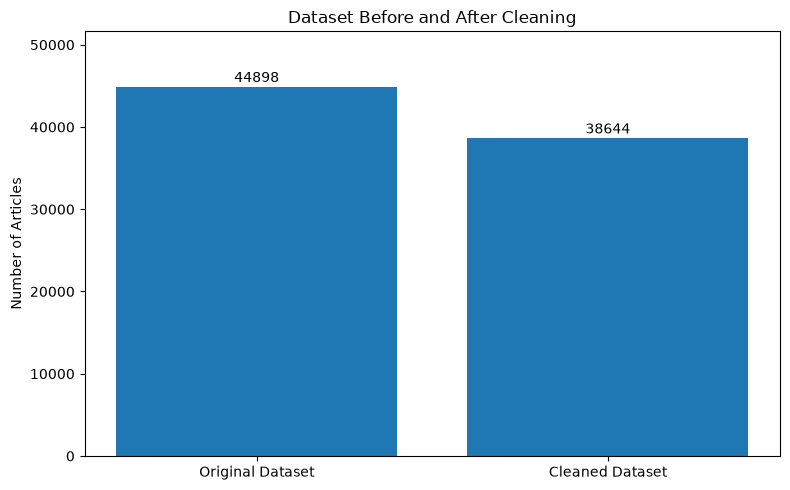

In [488]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Original Dataset", "Cleaned Dataset"],
    [original_total, cleaned_total]
)
plt.bar_label(bars, padding=1)
highest_value = max(original_total, cleaned_total)
plt.ylim(0, highest_value * 1.15)

plt.title("Dataset Before and After Cleaning")
plt.ylabel("Number of Articles")

plt.tight_layout()
plt.show()

<>:26: SyntaxWarning: invalid escape sequence '\P'
<>:26: SyntaxWarning: invalid escape sequence '\P'
C:\Users\Mohammad Salman\AppData\Local\Temp\ipykernel_26120\2826347382.py:26: SyntaxWarning: invalid escape sequence '\P'
  "P:\Project's\Fake-News-Detection-IUL-Data-Science-Project\screenshots/05_wordcloud_fake.png",


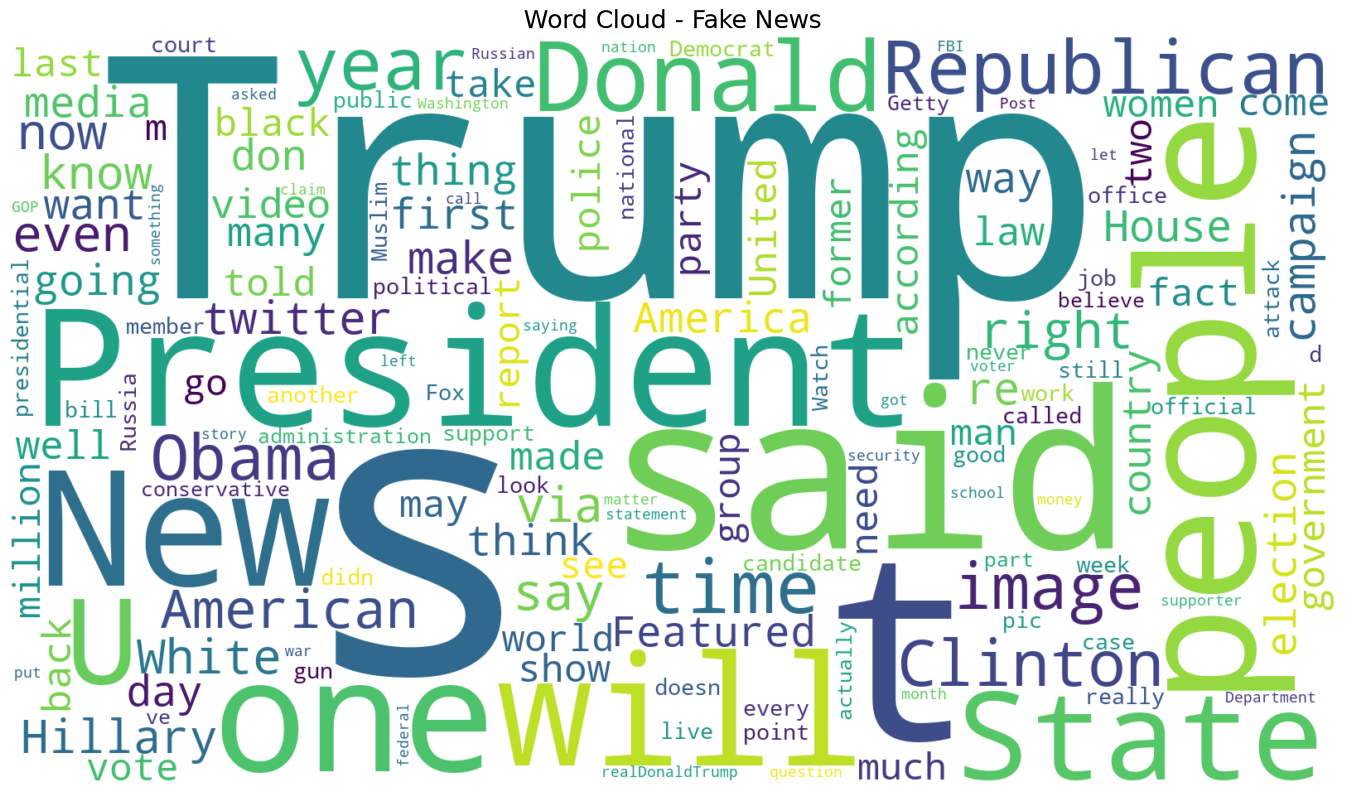

In [494]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

fake_text = " ".join(
    news_clean.loc[news_clean["label"] == 0, "text"]
    .dropna()
    .astype(str)
)

fake_wordcloud = WordCloud(
    width=1600,
    height=900,
    background_color="white",
    max_words=150,
    collocations=False
).generate(fake_text)

plt.figure(figsize=(14, 8))

plt.imshow(fake_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Fake News", fontsize=18)

plt.tight_layout()
plt.savefig(
    "P:\Project's\Fake-News-Detection-IUL-Data-Science-Project\screenshots/05_wordcloud_fake.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<>:23: SyntaxWarning: invalid escape sequence '\P'
<>:23: SyntaxWarning: invalid escape sequence '\P'
C:\Users\Mohammad Salman\AppData\Local\Temp\ipykernel_26120\735447204.py:23: SyntaxWarning: invalid escape sequence '\P'
  "P:\Project's\Fake-News-Detection-IUL-Data-Science-Project\screenshots/06_wordcloud_true.png",


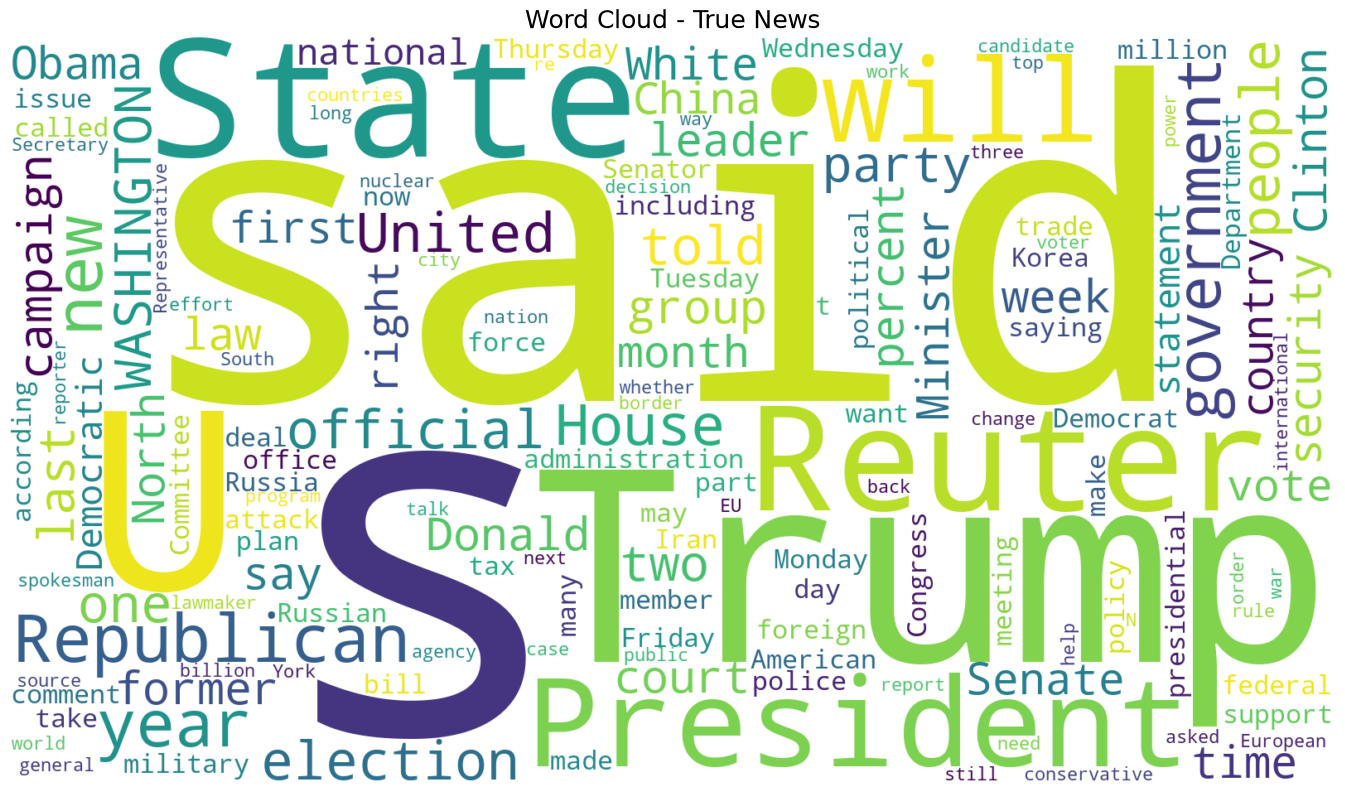

In [497]:
true_text = " ".join(
    news_clean.loc[news_clean["label"] == 1, "text"]
    .dropna()
    .astype(str)
)

true_wordcloud = WordCloud(
    width=1600,
    height=900,
    background_color="white",
    max_words=150,
    collocations=False
).generate(true_text)

plt.figure(figsize=(14, 8))

plt.imshow(true_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - True News", fontsize=18)

plt.tight_layout()
plt.savefig(
    "P:\Project's\Fake-News-Detection-IUL-Data-Science-Project\screenshots/06_wordcloud_true.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<>:45: SyntaxWarning: invalid escape sequence '\P'
<>:45: SyntaxWarning: invalid escape sequence '\P'
C:\Users\Mohammad Salman\AppData\Local\Temp\ipykernel_26120\688660890.py:45: SyntaxWarning: invalid escape sequence '\P'
  "P:\Project's\Fake-News-Detection-IUL-Data-Science-Project\screenshots/07_model_comparison.png",


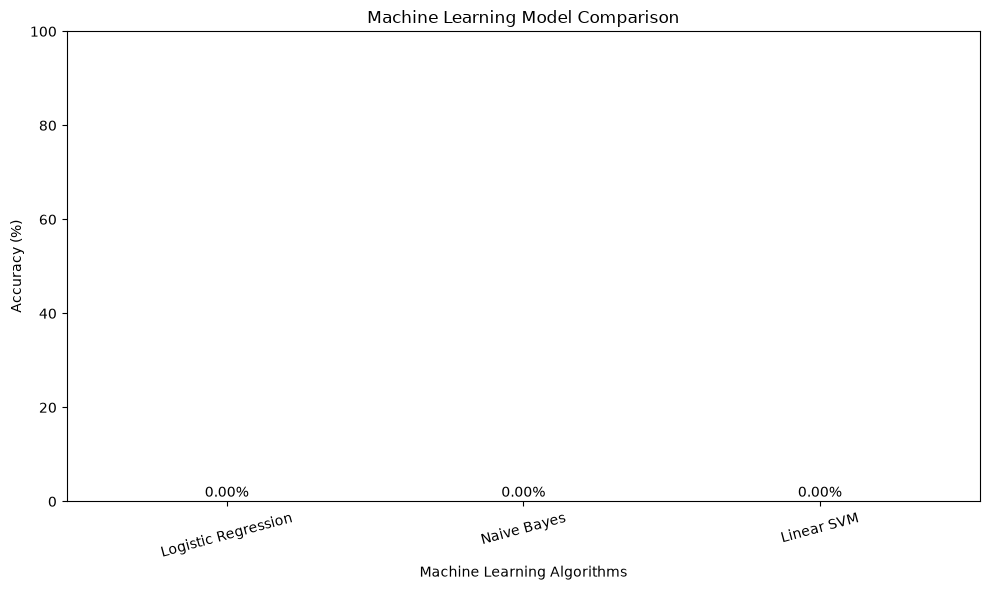

In [498]:
import matplotlib.pyplot as plt
import pandas as pd

# Replace these example entries with your ACTUAL model names and scores.
model_results = {
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM"
    ],
    "Accuracy": [
        # Enter actual accuracy percentages here
        0,
        0,
        0
    ]
}

model_comparison = pd.DataFrame(model_results)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    model_comparison["Model"],
    model_comparison["Accuracy"]
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "P:\Project's\Fake-News-Detection-IUL-Data-Science-Project\screenshots/07_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

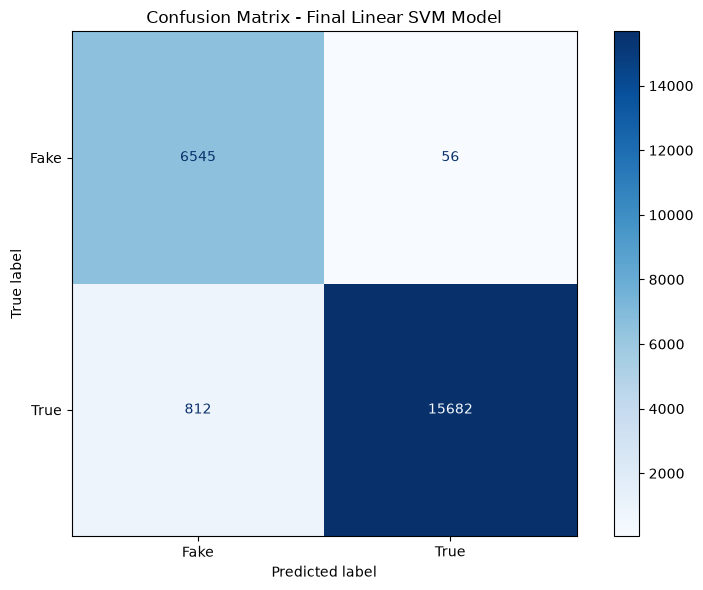

In [500]:
import matplotlib.pyplot as plt
import numpy as np  # 1. Import numpy
from sklearn.metrics import ConfusionMatrixDisplay

final_cm = [[6545, 56], [812, 15682]]

display = ConfusionMatrixDisplay(
    confusion_matrix=np.array(
        final_cm
    ),  # 2. Wrap your list in np.array()
    display_labels=["Fake", "True"],
)

fig, ax = plt.subplots(figsize=(8, 6))

display.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Final Linear SVM Model")
plt.tight_layout()

plt.savefig(
    r"P:\Project's\Fake-News-Detection-IUL-Data-Science-Project\screenshots\08_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

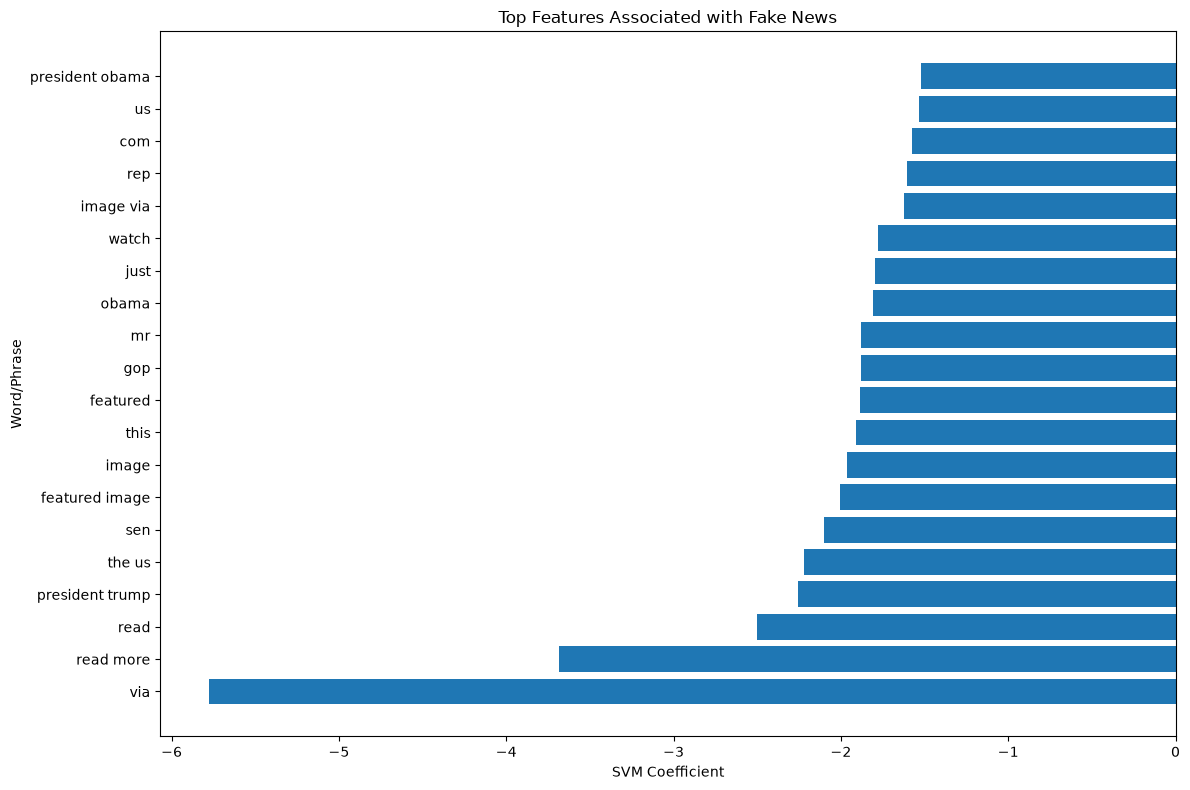

In [502]:
import matplotlib.pyplot as plt

top_fake = fake_features.sort_values("Weight")

plt.figure(figsize=(12, 8))

plt.barh(
    top_fake["Word/Phrase"],
    top_fake["Weight"]
)

plt.title("Top Features Associated with Fake News")
plt.xlabel("SVM Coefficient")
plt.ylabel("Word/Phrase")

plt.tight_layout()

plt.savefig(
    r"P:\Project's\Fake-News-Detection-IUL-Data-Science-Project\screenshots\09_feature_importance_fake.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

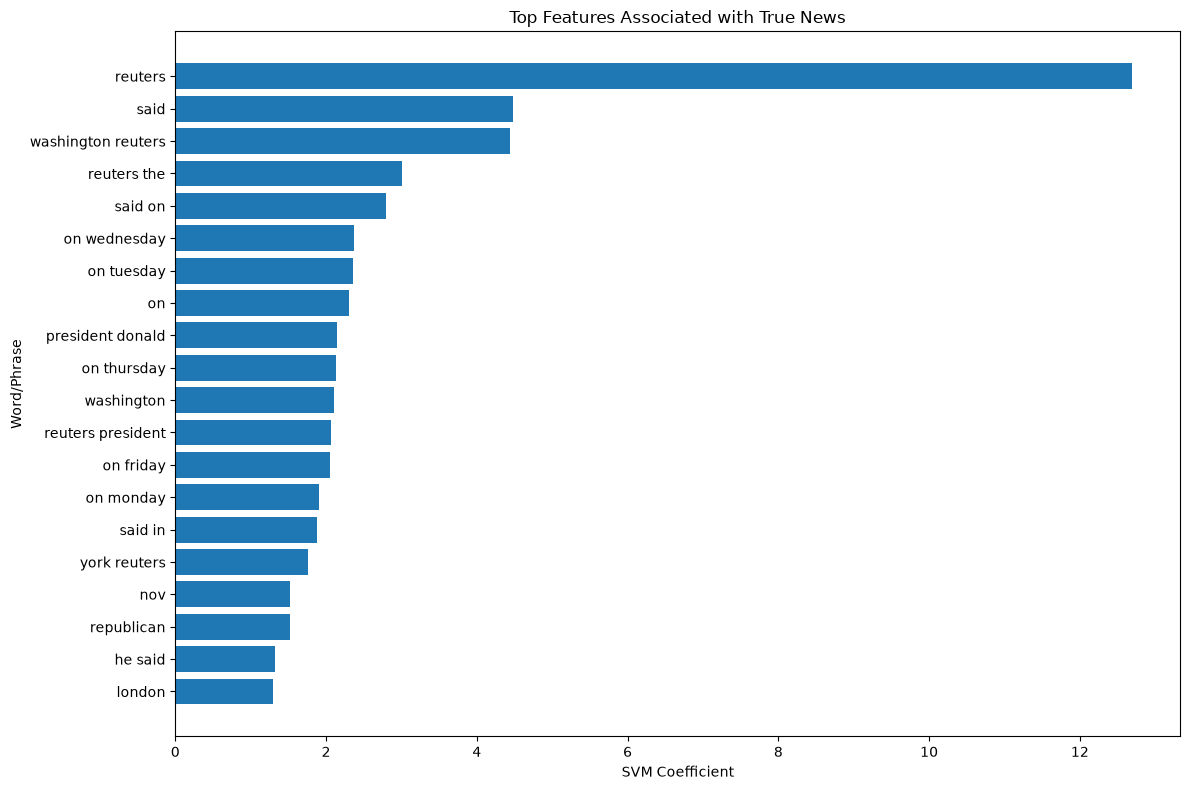

In [503]:
top_true = true_features.sort_values("Weight")

plt.figure(figsize=(12, 8))

plt.barh(
    top_true["Word/Phrase"],
    top_true["Weight"]
)

plt.title("Top Features Associated with True News")
plt.xlabel("SVM Coefficient")
plt.ylabel("Word/Phrase")

plt.tight_layout()

plt.savefig(
    r"P:\Project's\Fake-News-Detection-IUL-Data-Science-Project\screenshots\10_feature_importance_true.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()